# Medical Image Diagnosis with MRI: DICOM, the Lumbar Spine, and Evaluating MedGemma
**AI in Healthcare · Unit III · Lecture and lab**

A person with long-standing low back pain, and pain that runs down one leg, is referred for a lumbar spine MRI. The scanner produces about a hundred images in three separate series. A radiologist (a doctor who interprets medical images) scrolls through them, finds each disc level, and grades how narrow the spaces around the nerves have become. That report then helps the referring clinician decide what to do next.

Can a medical vision–language model read those images and produce the same grades? For an engineer, the more important question is: **how would we find out, and how could we be fooled?**

In this notebook you will learn enough anatomy and MRI physics to understand the task. You will then open real MRI files in DICOM format, display them correctly, and put MedGemma through a small, honest evaluation against expert labels for one patient.

> **Educational use only.** The images are de-identified research data from the RSNA 2024 Lumbar Spine Degenerative Classification dataset. Model outputs in this notebook are not clinical advice. Results from one patient cannot establish how well any model performs.

**Prerequisites:** Python, NumPy, pandas, and matplotlib; supervised classification; confusion-matrix metrics (sensitivity, specificity, PPV, NPV). No medical training is assumed.

**Companions:** [Medical foundation models lecture](../../../module2/lectures/session-05-medical-foundation-models.ipynb) · [Optional lab — Evaluating medical foundation models](../../../module2/labs/lab-06-medical-foundation-models.ipynb) · [Skin and tissue image demonstration](session-02-medical-image-analysis.ipynb)

## Learning objectives

By the end, you should be able to:

1. Describe the lumbar spine structures involved in degenerative stenosis, and name the MRI view used to grade each of the five RSNA conditions.
2. Explain how T1-weighted, T2-weighted, and STIR images differ, and what sagittal and axial planes show.
3. Explain how DICOM organizes images into patients, studies, series, and instances, and distinguish identifiers from image content.
4. Use DICOM geometry tags to find an image's plane, physical size, and the patient's left and right.
5. Load a series in the correct order, apply window/level, and overlay expert annotations.
6. Prompt MedGemma for structured output and convert its replies into labels that can be scored.
7. Score model labels against a reference standard and a baseline, and explain why one patient cannot establish clinical performance.
8. Use stress tests (repeat sampling, a blank image, a mirrored image) to reveal failure modes.

## Contents

**Part A — Lecture: concepts**

- [About the data used in this notebook](#About-the-data-used-in-this-notebook)

1. [The clinical problem: back pain, nerves, and narrowing](#1.-The-clinical-problem:-back-pain,-nerves,-and-narrowing)
2. [MRI in brief](#2.-MRI-in-brief)
3. [DICOM: how medical images are stored](#3.-DICOM:-how-medical-images-are-stored)
4. [Geometry: from pixels to millimetres and patient directions](#4.-Geometry:-from-pixels-to-millimetres-and-patient-directions)
5. [Displaying MRI: window/level, and what a model actually sees](#5.-Displaying-MRI:-window/level,-and-what-a-model-actually-sees)
6. [Two ways to build imaging AI](#6.-Two-ways-to-build-imaging-AI)
7. [How we will evaluate MedGemma](#7.-How-we-will-evaluate-MedGemma)

**Part B — Lab: hands-on (about 120 minutes)**

- [B1. The label tables](#B1.-The-label-tables)
- [B2. Loading DICOM series and reading their geometry](#B2.-Loading-DICOM-series-and-reading-their-geometry)
- [B3. Viewing the images and the expert annotations](#B3.-Viewing-the-images-and-the-expert-annotations)
- [B4. Asking MedGemma](#B4.-Asking-MedGemma)
- [B5. Scoring against the reference standard](#B5.-Scoring-against-the-reference-standard)
- [B6. Stress tests](#B6.-Stress-tests)
- [B7. Reflection, deliverables, and rubric](#B7.-Reflection,-deliverables,-and-rubric)

[References and further reading](#References-and-further-reading)

## Setup

**Software.** Python 3.10+ with `numpy`, `pandas` (2.1+), `matplotlib`, `pydicom`, and `Pillow`. The optional live-model path also needs `requests`. This notebook does not install anything. If something is missing, install it in your course environment, for example `pip install pydicom`.

**Data.** Your instructor provides the folder `data/rsna_study_100206310/`, next to this notebook (about 16 MB). It holds one study from the RSNA 2024 Lumbar Spine Degenerative Classification training set: three MRI series (96 DICOM files), plus the three label files filtered to this study. The full dataset is on the [Kaggle competition page](https://www.kaggle.com/competitions/rsna-2024-lumbar-spine-degenerative-classification). It needs a Kaggle account and acceptance of the competition rules, and its authors make it available for non-commercial use. Do not redistribute the files outside the class.

```text
data/rsna_study_100206310/
├── metadata/
│   ├── train.csv                        # severity grades (the labels)
│   ├── train_label_coordinates.csv      # where the expert placed each label
│   └── train_series_descriptions.csv    # which series is which
├── train_images/100206310/<series_id>/<instance_number>.dcm
└── medgemma_runs/run-<timestamp>.json   # saved MedGemma responses
```

**MedGemma.** With `RUN_MODEL = False` (the default) the notebook reads saved responses from `medgemma_runs/`, so no GPU, model download, or network is needed. With `RUN_MODEL = True`, it calls a MedGemma model served by [LM Studio](https://lmstudio.ai/) through its OpenAI-compatible endpoint. Each live session writes a **new** file, `run-<UTC timestamp>.json`, and never overwrites earlier files. If Jupyter runs inside WSL and LM Studio runs on Windows, set `LM_STUDIO_BASE_URL` to the Windows host address (for example, the default gateway shown by `ip route`), and enable network access in LM Studio's server settings.

**Compute.** Everything except the live model runs on an ordinary laptop CPU in seconds. A live run makes 17 model calls (about 2 minutes on the instructor's setup, plus model loading). Local inference puts a heavy, sustained load on the GPU: save your work and close other GPU-heavy applications before setting `RUN_MODEL = True`.

In [1]:
import base64
import hashlib
import io
import json
import os
import re
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydicom
from IPython.display import Markdown, display
from PIL import Image, ImageOps

print("pydicom", pydicom.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

pydicom 3.0.2 | pandas 2.2.3 | numpy 1.26.4


In [2]:
# ---- Data location (relative to this notebook) ----
STUDY_ID = "100206310"
DATA_ROOT = Path("data/rsna_study_100206310")
META_ROOT = DATA_ROOT / "metadata"
IMAGE_ROOT = DATA_ROOT / "train_images" / STUDY_ID

# ---- MedGemma access ----
# False: read saved responses (no model, GPU, or network needed).
# True:  call MedGemma through LM Studio's OpenAI-compatible endpoint.
RUN_MODEL = False
LM_STUDIO_BASE_URL = os.getenv("LM_STUDIO_BASE_URL", "http://localhost:1234/v1")
MODEL_ID = os.getenv("LM_STUDIO_MODEL", "medgemma-1.5-4b-it")

# Saved responses. None = use the newest run file; or set a specific Path.
RUN_DIR = DATA_ROOT / "medgemma_runs"
CACHE_FILE = None

assert IMAGE_ROOT.exists(), f"Image folder not found: {IMAGE_ROOT.resolve()} (see the Data note above)"
print("Images:", IMAGE_ROOT)
print("Mode  :", "LIVE model calls" if RUN_MODEL else "saved responses")

Images: data/rsna_study_100206310/train_images/100206310
Mode  : saved responses


---
# Part A — Lecture: concepts

## About the data used in this notebook

Everything in this notebook comes from **one patient**: a single lumbar spine MRI study (`study_id 100206310`) from the training set of the [RSNA 2024 Lumbar Spine Degenerative Classification](https://www.kaggle.com/competitions/rsna-2024-lumbar-spine-degenerative-classification) dataset. The images are real but de-identified. The terms used below (sagittal, axial, T1, T2, DICOM) are explained in sections 2–4.

**Images: 3 series, 96 DICOM files, about 16 MB**

| Series | View | Slices | Image size | Pixel size | Slice thickness |
|---|---|---|---|---|---|
| Sagittal T2/STIR | Side view, slicing from the patient's right to left | 18 | 462 × 448 pixels (about 247 × 240 mm) | 0.54 mm | 4 mm |
| Sagittal T1 | Side view, slicing from the patient's right to left | 18 | 512 × 512 pixels (about 350 × 350 mm) | 0.68 mm | 4 mm |
| Axial T2 | Cross-sections, from the head end downwards, in five tilted blocks | 60 | 320 × 320 pixels (160 × 160 mm) | 0.5 mm | 3.5 mm |

All images are 12-bit greyscale. The files were de-identified, so their headers are sparse. For example, `Modality` and the patient's name are absent, and `PatientID` is simply the study number.

**Labels: three CSV files, filtered to this study**

| File | Contents for this patient |
|---|---|
| `train.csv` | 25 severity grades: 5 conditions × 5 disc levels (L1/L2 to L5/S1), each Normal/Mild, Moderate, or Severe |
| `train_label_coordinates.csv` | 25 points showing the slice and pixel where the radiologist made each grading |
| `train_series_descriptions.csv` | The name of each of the 3 series (for example, "Axial T2") |

This patient has substantial degenerative disease: most of the 25 grades are Moderate or Severe, and L4/L5 is the most affected level. You will count the grades yourself in Exercise 1.

**Saved model responses.** `medgemma_runs/` holds MedGemma's replies to the 17 prompts used in Part B, so the notebook runs without a GPU.

**What this data can and cannot show**

- The grades are **one radiologist's reading**: training-set studies were annotated only once ([Richards et al., 2026](https://pubs.rsna.org/doi/10.1148/ryai.250480)). Treat them as a reference standard, not certain truth.
- One patient can **reveal how a model behaves and fails**. It cannot measure accuracy, because the 25 labels share one person's anatomy, one scanner, and one annotator.
- The dataset is available for non-commercial use under the Kaggle competition rules. Keep these files within the class.

## 1. The clinical problem: back pain, nerves, and narrowing

### 1.1 What is in the lower back?

The **spine** is a stack of bones called **vertebrae**. The lower back is the **lumbar** region, with five vertebrae named **L1 to L5** from top to bottom. Below L5 is the **sacrum**, whose top segment is called **S1**.

Between neighbouring vertebrae sits an **intervertebral disc**: a cushion with a water-rich, gel-like centre and a tough fibrous outer ring. A disc **level** is named after the two bones around it. For example, **L4/L5** is the disc between L4 and L5. The five lumbar levels are L1/L2, L2/L3, L3/L4, L4/L5, and L5/S1.

```text
 Side view (sagittal), simplified

   SUPERIOR (towards the head)
      ┌──────┐
      │  L1  │   ▒▒  ← spinal canal (behind the bones)
      └──────┘   ▒▒
       ====  L1/L2 disc
      ┌──────┐   ▒▒
      │  L2  │   ▒▒
      └──────┘   ▒▒
       ====  L2/L3        … and so on down to …
      ┌──────┐   ▒▒
      │  L5  │   ▒▒
      └──────┘   ▒▒
       ====  L5/S1 disc
      ┌──────┐
      │  S1  │  (sacrum)
      └──────┘
   INFERIOR (towards the feet)
   ANTERIOR (front) ◄────► POSTERIOR (back)
```

### 1.2 Where do the nerves run?

Behind the discs and vertebral bodies is the **spinal canal**. It contains the **thecal sac**, a membrane tube filled with **cerebrospinal fluid (CSF)** in which nerve roots float. In the lower back, the spinal cord itself has usually ended (around L1–L2). Below that, the canal holds a bundle of nerve roots called the **cauda equina** ("horse's tail").

At each level, a pair of nerve roots leaves the spine, one on each side. On its way out, a root passes through two narrow spaces:

- the **lateral recess** (also called the **subarticular zone**): a gutter at the side of the canal, under the facet joint;
- the **neural foramen**: a window between neighbouring vertebrae through which the root exits. It is normally cushioned by fat.

```text
 Cross-section (axial) at one disc level, simplified.
 Drawn in radiological convention: viewed from the feet, so the
 PATIENT'S RIGHT is on the LEFT of the picture.

                     ANTERIOR (front)
               ┌─────────────────────────┐
               │      intervertebral     │
               │           disc          │
               └─────────────────────────┘
   right       ┌──┐  ┌───────────────┐  ┌──┐       left
   neural ◄──  │  │  │  thecal sac   │  │  │  ──►  neural
   foramen     └──┘  │ (CSF + nerve  │  └──┘       foramen
          right      │    roots)     │     left
          lateral ►  └───────────────┘  ◄ lateral
          recess    facet  ═══════  facet   recess
                    joint  ligamentum joint
                           flavum
                     POSTERIOR (back)
   Patient's RIGHT  ◄──────────────────►  Patient's LEFT
```

### 1.3 What goes wrong: degenerative stenosis

With age and wear, discs lose water and height and may bulge backwards. The **facet joints** (small joints at the back of each vertebra) can enlarge, and the **ligamentum flavum** (the ligament forming the back wall of the canal) can thicken. Each change takes up space.

**Stenosis** means narrowing. Degenerative changes can narrow the central canal, a lateral recess, or a foramen. If the narrowing squeezes a nerve root, the person may feel pain, numbness, or weakness in the leg.

Narrowing on an image does not prove that it causes symptoms. Degenerative findings are common in people with no back pain and become more common with age. In one systematic review, disc degeneration was reported in 37% of asymptomatic 20-year-olds and 96% of asymptomatic 80-year-olds ([Brinjikji et al., 2015](https://www.ajnr.org/content/36/4/811)).

So the radiologist grades **anatomy**. The clinician then combines that grading with the person's symptoms and examination. The AI task in this notebook is anatomical grading, which is far narrower than "diagnosing the cause of back pain".

### 1.4 The five conditions in the RSNA dataset

The RSNA 2024 dataset contains MRI studies from 2,697 patients at 8 institutions in 6 countries. Volunteer neuroradiologists and musculoskeletal radiologists graded five conditions at each of the five levels ([Richards et al., 2026](https://pubs.rsna.org/doi/10.1148/ryai.250480)). The table also shows which series the annotators used to grade each condition.

| Condition | Where the narrowing is | Sides | Series used by annotators | What narrowing looks like (simplified) |
|---|---|---|---|---|
| **Spinal canal stenosis** | Central canal | One (midline) | Sagittal "T2-like" | The bright CSF around the nerve roots is squeezed out |
| **Neural foraminal narrowing** | Foramen | Left and right | Sagittal T1 | The bright fat around the exiting root is reduced |
| **Subarticular stenosis** | Lateral recess | Left and right | Axial T2 | The recess narrows and the root is crowded |

That gives **5 condition columns × 5 levels = 25 labels per study**. Annotators used a 4-point scale (normal, mild, moderate, severe), which was then collapsed into three classes by merging normal and mild: **Normal/Mild, Moderate, Severe**.

The classes are imbalanced. Across all spinal canal grades in the dataset, 85.4% were Normal/Mild, 8.8% Moderate, and 5.9% Severe.

**How good is the "ground truth"?** Training-set studies were **annotated once**, by one radiologist per condition. Test-set studies were re-annotated until two annotators agreed. The dataset authors note that grading degenerative disease is inherently subjective ([Richards et al., 2026](https://pubs.rsna.org/doi/10.1148/ryai.250480)). Our patient comes from the training set, so its labels are **one expert's reading**. That makes them a **reference standard**, not certain truth.

### 1.5 Clinical purpose versus computational task

Before choosing a model, separate the real-world purpose from the small, testable task delegated to software.

| Question | Answer for this notebook |
|---|---|
| Clinical purpose | Support consistent grading of lumbar stenosis in a radiology report |
| Not the purpose | Diagnosing the cause of pain, or deciding on treatment or surgery |
| Intended user | A radiologist who reviews every output |
| Decision time | After the scan is complete, before the report is signed |
| Unit of analysis | One **study**: one MRI visit, here one patient |
| Input | Three MRI series (sagittal T1, sagittal T2/STIR, axial T2) |
| Output | One of three grades for each of the 25 condition-level labels |
| Computational task | 25 three-class classification problems per study |

Keep three units apart throughout the lab. A **study** is one MRI visit. A **slice** (DICOM *instance*) is one 2D image. A **label** is one condition-level grade. This study has 96 slices but 25 labels.

## 2. MRI in brief

### 2.1 How MRI makes an image

**Magnetic resonance imaging (MRI)** places the body in a strong magnetic field and sends radio-frequency pulses. Hydrogen nuclei, mostly in water and fat, respond and emit signals. Different tissues return to equilibrium ("relax") at different rates, and this difference creates image contrast. MRI uses no ionizing radiation.

A scan acquires a stack of thin 2D **slices**. One run of one pulse sequence in one orientation is a **series**.

### 2.2 Weightings: why the same anatomy looks different

By changing the timing of the pulses, the scanner emphasizes different tissue properties. This is called the **weighting**.

| Sequence | Fluid (CSF, healthy disc) | Fat | Used in this dataset for |
|---|---|---|---|
| **T1-weighted** | Dark | Bright | Neural foramina: the bright fat around each nerve root makes narrowing visible |
| **T2-weighted** | Bright | Intermediate to bright | Spinal canal and lateral recesses: bright CSF outlines the nerve roots |
| **STIR** (short tau inversion recovery) | Bright | Suppressed (dark) | Fluid-sensitive images; the dataset accepts STIR as a "T2-like" sagittal series |

Healthy discs contain water and look bright on T2. Degenerated discs lose water and look darker.

### 2.3 Planes

| Plane | Viewpoint | In this study |
|---|---|---|
| **Sagittal** | Side view, slicing left to right | Sagittal T1 and Sagittal T2/STIR, 18 slices each |
| **Axial** | Cross-section, slicing head to feet | Axial T2, 60 slices |
| **Coronal** | Front view | Not used here |

### 2.4 MRI numbers have no fixed unit

In CT, pixel values are calibrated to **Hounsfield units**, where water is 0 by definition. MRI intensities have **no such fixed scale**. The same tissue can have very different values on different scanners, coils, or settings.

This matters for AI. A model trained at one hospital can meet different intensity distributions at another, which is a form of **dataset shift**. Normalizing each image helps, but it does not remove differences in contrast, noise, or protocol.

## 3. DICOM: how medical images are stored

### 3.1 What DICOM is

**DICOM** (Digital Imaging and Communications in Medicine) is the international standard for medical images. It defines both a file format and a network protocol. Scanners send DICOM objects to a **PACS** (picture archiving and communication system), where radiologists view them.

Each DICOM file has two parts:

1. a **header**: a list of **data elements**, each identified by a tag `(group, element)`, a keyword, and a value;
2. the **pixel data**: the image itself, often with 12–16 bits per pixel.

### 3.2 The hierarchy

| Level | Meaning | DICOM identifier | In the RSNA files |
|---|---|---|---|
| Patient | The person | `PatientID (0010,0020)` | Replaced by the study number |
| **Study** | One imaging visit | `StudyInstanceUID (0020,000D)` | `study_id` column; top folder |
| **Series** | One sequence in one plane | `SeriesInstanceUID (0020,000E)` | `series_id` column; sub-folder |
| **Instance** | One image (slice) | `SOPInstanceUID (0008,0018)`, `InstanceNumber (0020,0013)` | `<instance_number>.dcm` |

### 3.3 Identifiers are not content

A **UID** (unique identifier) tells a computer which object it is handling. It says nothing about anatomy or disease.

Headers can also hold personal information such as names, birth dates, and hospital numbers. Text can even be "burned into" the pixels. **De-identification** removes or replaces such data before research use. The RSNA contributing sites de-identified their data, and many tags (for example `Modality` and the patient's name) are absent from these files.

### 3.4 DICOM compared with PNG and JPEG

| Property | PNG / JPEG | DICOM |
|---|---|---|
| Typical bit depth | 8 bits (256 grey levels) | 12–16 bits (here 12 bits: 4,096 levels) |
| Metadata | Minimal | Rich: identifiers, acquisition settings, geometry |
| Physical scale | Pixels only | Millimetres via `PixelSpacing` and positions |
| Grouping | Single picture | Instance → series → study |
| Clinical use | Exports and teaching | Standard for clinical storage and exchange (DICOM files can themselves use JPEG-family compression) |

Let us read the header of one axial slice. pydicom reads it as a `Dataset`, whose elements we can access by keyword.

In [3]:
example_path = IMAGE_ROOT / "1012284084" / "46.dcm"   # one axial T2 slice
example = pydicom.dcmread(example_path)

# Show every header element except the large pixel block.
header_rows = [
    {"tag": str(elem.tag), "keyword": elem.keyword, "value": str(elem.value)[:60]}
    for elem in example
    if elem.keyword != "PixelData"
]
display(pd.DataFrame(header_rows))
print("Pixel array:", example.pixel_array.shape, example.pixel_array.dtype,
      "| min", example.pixel_array.min(), "| max", example.pixel_array.max())

,tag,keyword,value
0,"(0008,0018)",SOPInstanceUID,100206310.1.46
1,"(0008,0023)",ContentDate,20240503
2,"(0008,0033)",ContentTime,223741.892820
3,"(0008,103E)",SeriesDescription,T2
4,"(0010,0020)",PatientID,100206310
5,"(0018,0050)",SliceThickness,3.5
6,"(0018,0088)",SpacingBetweenSlices,3.5
7,"(0018,5100)",PatientPosition,HFS
8,"(0020,000D)",StudyInstanceUID,100206310
9,"(0020,000E)",SeriesInstanceUID,100206310.1012284084


Pixel array: (320, 320) uint16 | min 0 | max 1259


The header has only 26 elements because the files were de-identified. `SeriesDescription` says only `T2`. The fuller description ("Axial T2") comes from the dataset's CSV file, a reminder that metadata can live outside the image.

The pixel values are integers. With `BitsStored = 12`, they could range from 0 to 4,095, but this slice uses only part of that range.

## 4. Geometry: from pixels to millimetres and patient directions

### 4.1 Size

- `PixelSpacing` gives the physical size of one pixel in mm (row spacing, column spacing).
- `SliceThickness` is the thickness of the tissue slab captured by one slice.
- `SpacingBetweenSlices` is the distance between slice centres. If it is larger than the thickness, there are small gaps.

**Worked example.** The axial slice above is 320 × 320 pixels with 0.5 mm spacing. The **field of view** is 320 × 0.5 = **160 mm** on each side. The sagittal T1 series has 512 pixels at 0.684 mm, giving about **350 mm**: enough to show the whole lumbar spine.

### 4.2 Direction: the patient coordinate system

DICOM places every image in a 3D coordinate system attached to the patient, in millimetres ([DICOM PS3.3 §C.7.6.2.1.1](https://dicom.nema.org/medical/dicom/current/output/chtml/part03/sect_C.7.6.2.html)):

| Axis | Increases towards |
|---|---|
| +x | the patient's **left** |
| +y | the patient's **posterior** (back) |
| +z | the patient's **head** (superior) |

This is often called **LPS** (left, posterior, superior).

- `ImagePositionPatient` = the (x, y, z) position in mm of the centre of the top-left pixel.
- `ImageOrientationPatient` = six numbers. The first three are the direction you move in when going **along a row** (left to right on screen). The last three are the direction you move in when going **down a column**.

The cross product of the two directions gives the **slice normal**: the direction perpendicular to the image. Its largest component tells us the plane.

**Worked example.** For an axial slice, the row direction is about (1, 0, 0) and the column direction about (0, 1, 0). Their cross product is (0, 0, 1), which points along z (head–feet), so the slices are stacked from head to feet: **axial**. A normal along x (left–right) means **sagittal**.

### 4.3 Left and right on screen

A row direction of +x means that moving right across the screen moves towards the **patient's left**. That is the **radiological convention**: an axial image is viewed as if looking up from the patient's feet, so the patient's left appears on the viewer's right. Getting this wrong swaps left and right labels, a classic and dangerous error.

In [4]:
row_dir = np.array(example.ImageOrientationPatient[:3], dtype=float)
col_dir = np.array(example.ImageOrientationPatient[3:], dtype=float)
normal = np.cross(row_dir, col_dir)

print("Row direction   :", row_dir.round(3), "→ moving right on screen moves towards the patient's",
      "LEFT" if row_dir[0] > 0 else "RIGHT")
print("Column direction:", col_dir.round(3))
print("Slice normal    :", normal.round(3), "→ largest component on axis",
      "xyz"[int(np.argmax(np.abs(normal)))])
print("Field of view   :", example.Rows * float(example.PixelSpacing[0]), "mm ×",
      example.Columns * float(example.PixelSpacing[1]), "mm")

Row direction   : [ 0.999  0.03  -0.042] → moving right on screen moves towards the patient's LEFT
Column direction: [-0.02   0.976  0.216]
Slice normal    : [ 0.048 -0.215  0.975] → largest component on axis z
Field of view   : 160.0 mm × 160.0 mm


The normal is not exactly (0, 0, 1). This axial series is acquired in tilted blocks so that slices lie roughly parallel to each disc, and the lower discs are tilted more. You will see this in the lab.

## 5. Displaying MRI: window/level, and what a model actually sees

### 5.1 Window/level

A screen shows about 256 grey levels. A 12-bit image has up to 4,096. **Window/level** chooses which range of raw values to stretch across the screen:

$$
I_{\text{display}} = 255 \times \frac{\operatorname{clip}(I_{\text{raw}},\ L - W/2,\ L + W/2) - (L - W/2)}{W}
$$

- $I_{\text{raw}}$ — the stored pixel value (arbitrary MRI units);
- $L$ — the **level** (window centre): the middle of the range of interest;
- $W$ — the **window width**: how wide that range is;
- `clip` sets values below $L - W/2$ to that lower bound (black) and values above $L + W/2$ to the upper bound (white).

**Worked example.** The header of the axial slice we opened (instance 46) suggests $L = 576$ and $W = 1235$. The displayed range is $576 - 617.5 = -41.5$ to $576 + 617.5 = 1193.5$. A raw value of 600 becomes $255 \times (600 + 41.5) / 1235 \approx 132$, a mid grey. Every raw value above 1193.5 becomes pure white, so differences between those bright pixels are lost on screen.

A narrow window increases contrast within a small range. A wide window shows more of the range with less contrast.

### 5.2 MRI has no universal presets

CT viewers have standard presets such as "bone" or "lung" because Hounsfield units are fixed. MRI has none. The `WindowCenter`/`WindowWidth` values in the header are suggestions from the scanner or technologist. A common alternative is a **percentile window**, for example the 1st to 99th percentile of the slice's own values.

### 5.3 What MedGemma receives

To send a slice to MedGemma we:

1. apply a window (12-bit → 8-bit), discarding grey-level detail;
2. save it as a PNG picture of one 2D slice;
3. let the model resize it: MedGemma's image encoder normalizes images to 896 × 896 pixels and turns each image into 256 tokens ([MedGemma model card](https://developers.google.com/health-ai-developer-foundations/medgemma/model-card)).

A radiologist scrolls through every slice of three series at full bit depth. The model in our setup sees **one compressed 2D picture per request**. Keep that gap in mind when interpreting its answers.

## 6. Two ways to build imaging AI

| | **Task-specific model** | **Foundation vision–language model** |
|---|---|---|
| Example | A convolutional neural network (CNN) trained on thousands of labelled lumbar MRIs, as in the Kaggle competition | MedGemma, prompted with an image and instructions |
| How it learns this task | Supervised training on this exact label set | Broad pretraining and medical adaptation; no training on our labels (**zero-shot**) |
| Output | Calibrated class probabilities for fixed labels | Free text, which we must parse into labels |
| Main strengths | Usually stronger on the narrow task it was trained for | Flexible; no task-specific training data needed |
| Main risks | Needs large labelled data; fails under dataset shift | Fluent but unsupported answers; format errors; untested on many tasks |

### 6.1 MedGemma in one paragraph

**MedGemma** is a collection of Google models built on **Gemma 3**, a decoder-only language model, with a **SigLIP-based image encoder** pretrained on de-identified medical data. **MedGemma 1.5 4B** (released 13 January 2026) adds support for 3D CT and MRI volumes, among other image types. Details of the architecture are in the [foundation models lecture](../../../module2/lectures/session-05-medical-foundation-models.ipynb).

The model card sets clear limits ([MedGemma model card](https://developers.google.com/health-ai-developer-foundations/medgemma/model-card), checked 9 October 2026):

> "MedGemma's multimodal capabilities have been primarily evaluated on single-image tasks."
>
> "MedGemma has not been evaluated in use cases that involve comprehension of multiple images."
>
> "The outputs generated by MedGemma are not intended to directly inform clinical diagnosis, patient management decisions, treatment recommendations, or any other direct clinical practice applications."

### 6.2 Our setup is not the reported model

The saved responses come from `medgemma-1.5-4b-it` served by LM Studio as a **4-bit quantized GGUF** file (`Q4_K_S`). Quantization stores the weights at lower precision to save memory and can change outputs. We also send **2D PNG slices through a chat API**, not 3D volumes prepared as described by the model's developers. Our results therefore describe **this setup on this patient**. They do not measure MedGemma's 3D MRI capability or its published benchmark performance.

## 7. How we will evaluate MedGemma

### 7.1 Four experiments

| ID | Experiment | Images sent | What it tests |
|---|---|---|---|
| **E0** | Sanity check | One slice from each series, separately | Can the model name the modality, body region, and plane? We can check this against the DICOM geometry. |
| **E1** | Naive whole-study prompt | The middle slice of each series, together in one request | All 25 grades at once from arbitrary slices. This is how a first attempt often looks. |
| **E2** | Expert-guided prompts | The slice where the expert placed each annotation; one condition per request | Best-case input: the right slice, the right view, a narrow question |
| **E3** | Stress tests | Repeated, blank, and mirrored images | Consistency, refusal to answer without evidence, and left/right reasoning |

**A warning about E2.** E2 chooses slices using the expert's annotation coordinates, which are part of the reference standard. A deployed system would not have them. E2 is a best-case probe of the model, not a usable pipeline, and its scores are optimistic.

### 7.2 Metrics

- **Format compliance**: how many of the 25 labels came back as an allowed grade? "Cannot assess" is allowed and counted separately; anything else is invalid.
- **Exact agreement**: labels where the model grade equals the reference grade, out of all 25.
- **High-grade detection**: treat **Moderate or Severe** as "positive" (clinically relevant narrowing). Then compute sensitivity, specificity, positive predictive value (PPV), and negative predictive value (NPV) on the labels the model actually graded.
- **Baseline**: always answer "Normal/Mild", the most common class in the dataset. A model must beat this trivial rule to show it is reading the image.

**Worked calculation (hypothetical model).** Suppose 16 of 25 reference labels are positive and 9 are negative, and a model calls 10 labels positive, of which 8 are truly positive.

| | Reference positive | Reference negative |
|---|---|---|
| Model positive | TP = 8 | FP = 2 |
| Model negative | FN = 8 | TN = 7 |

- Sensitivity = TP / (TP + FN) = 8/16 = **50%**: half the narrowed sites were found.
- Specificity = TN / (TN + FP) = 7/9 = **78%**.
- PPV = TP / (TP + FP) = 8/10 = **80%**: when it says "narrowed", it is usually right.
- NPV = TN / (TN + FN) = 7/15 = **47%**: a "normal" answer is wrong more than half the time.

### 7.3 Why one patient cannot establish performance

- The 25 labels are **not independent**: they share one person's anatomy, one scanner, and one image quality.
- The reference is **one annotator's** reading.
- One patient covers a tiny part of the variety of ages, diseases, scanners, and sites.
- A confidence interval computed as if the 25 labels were independent would be falsely narrow, so we do not report one.

A real evaluation would need hundreds of held-out studies, ideally from sites not used in development, a test set with multiple annotators, prespecified metrics, subgroup analysis, and a study of how radiologists actually use the output.

### Review questions (Part A)

1. Why is "grading stenosis on MRI" a narrower task than "diagnosing the cause of back pain"?
2. Which series would you look at to grade left foraminal narrowing at L4/L5, and why does T1 weighting help?
3. A file is named `20.dcm`. Which DICOM tag, not the file name, should decide its order in the series?
4. A slice has `ImageOrientationPatient = [0, 1, 0, 0, 0, -1]`. What is its plane?
5. Why can't you reuse a CT "bone window" on MRI?
6. Give two reasons why MedGemma's published benchmark scores do not predict its accuracy in this notebook.
7. Why are the E2 results optimistic?

---
# Part B — Lab: hands-on

**Goal:** load one patient's lumbar MRI study correctly, then evaluate MedGemma's grading against the expert reference and a baseline.

| Section | Activity | Time |
|---|---|---|
| Setup | Run the setup cells; check the data folder | 5 min |
| B1 | Label tables: reshape and inspect | 15 min |
| B2 | DICOM series loading and geometry | 20 min |
| B3 | Display, window/level, expert annotations | 20 min |
| B4 | MedGemma experiments E0–E2 | 25 min |
| B5 | Scoring against the reference and a baseline | 15 min |
| B6 | Stress tests (E3) | 10 min |
| B7 | Reflection and submission | 10 min |

**Deliverables:** this notebook, run top to bottom, with your code and written answers for Exercises 1–7, and the reflection in B7. The grading rubric is in B7.

Run all Part A cells first: Part B uses `IMAGE_ROOT`, `RUN_MODEL`, and the imports from the setup cells.

## B1. The label tables

The dataset gives three CSV files:

| File | One row means | Key columns |
|---|---|---|
| `train_series_descriptions.csv` | One series | `study_id`, `series_id`, `series_description` |
| `train.csv` | One **study**, with 25 grade columns | `study_id`, `spinal_canal_stenosis_l1_l2`, … |
| `train_label_coordinates.csv` | One **annotation point** placed by the expert | `series_id`, `instance_number`, `condition`, `level`, `x`, `y` |

In [5]:
df_series = pd.read_csv(META_ROOT / "train_series_descriptions.csv")
df_train = pd.read_csv(META_ROOT / "train.csv")
df_coords = pd.read_csv(META_ROOT / "train_label_coordinates.csv")

for name, df in [("series", df_series), ("train", df_train), ("coordinates", df_coords)]:
    print(f"{name:12s}: {df.shape[0]:3d} rows × {df.shape[1]:2d} columns")
display(df_series)

series      :   3 rows ×  3 columns
train       :   1 rows × 26 columns
coordinates :  25 rows ×  7 columns


,study_id,series_id,series_description
0,100206310,1012284084,Axial T2
1,100206310,1792451510,Sagittal T2/STIR
2,100206310,2092806862,Sagittal T1


`train.csv` is **wide**: one row with 25 grade columns. For scoring we want a **long** table with one row per label, with columns `condition`, `level`, and `grade_true`.

- `melt` turns columns into rows: each of the 25 grade columns becomes one row holding its column name and value.
- The column name (for example `left_neural_foraminal_narrowing_l4_l5`) contains both the condition and the level. A regular expression splits it at the final `_lX_lY` or `_l5_s1` part.

In [6]:
LEVELS = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
CONDITIONS = [
    "spinal_canal_stenosis",
    "left_neural_foraminal_narrowing",
    "right_neural_foraminal_narrowing",
    "left_subarticular_stenosis",
    "right_subarticular_stenosis",
]
GRADES = ["Normal/Mild", "Moderate", "Severe"]

truth = df_train.melt(id_vars="study_id", var_name="column", value_name="grade_true")
parts = truth["column"].str.extract(r"^(?P<condition>.+)_(?P<lvl>l\d_[ls]\d)$")
truth["condition"] = parts["condition"]
truth["level"] = parts["lvl"].str.upper().str.replace("_", "/")   # 'l4_l5' -> 'L4/L5'
truth = truth[["condition", "level", "grade_true"]]

assert len(truth) == 25 and truth["grade_true"].isin(GRADES).all()
display(truth.head(6))

# Pivot back into a readable 5 × 5 grid: one row per condition, one column per level.
truth_grid = truth.pivot(index="condition", columns="level", values="grade_true").loc[CONDITIONS, LEVELS]

SEVERITY_STYLE = {
    "Normal/Mild": "background-color:#d4edda;color:#155724",
    "Moderate": "background-color:#fff3cd;color:#856404",
    "Severe": "background-color:#f8d7da;color:#721c24",
}

def style_grades(grid):
    return grid.style.map(lambda v: SEVERITY_STYLE.get(v, "background-color:#e2e3e5"))

display(Markdown("**Reference grades for study 100206310**"))
display(style_grades(truth_grid))

,condition,level,grade_true
0,spinal_canal_stenosis,L1/L2,Normal/Mild
1,spinal_canal_stenosis,L2/L3,Normal/Mild
2,spinal_canal_stenosis,L3/L4,Moderate
3,spinal_canal_stenosis,L4/L5,Severe
4,spinal_canal_stenosis,L5/S1,Normal/Mild
5,left_neural_foraminal_narrowing,L1/L2,Normal/Mild


**Reference grades for study 100206310**

level,L1/L2,L2/L3,L3/L4,L4/L5,L5/S1
condition,,,,,
spinal_canal_stenosis,Normal/Mild,Normal/Mild,Moderate,Severe,Normal/Mild
left_neural_foraminal_narrowing,Normal/Mild,Moderate,Moderate,Severe,Moderate
right_neural_foraminal_narrowing,Moderate,Moderate,Severe,Moderate,Normal/Mild
left_subarticular_stenosis,Normal/Mild,Normal/Mild,Moderate,Severe,Moderate
right_subarticular_stenosis,Normal/Mild,Normal/Mild,Moderate,Moderate,Moderate


### ✏️ Exercise 1 — Understand the labels

1. Use `truth` to count how many of the 25 labels are Normal/Mild, Moderate, and Severe. How does this patient compare with the dataset-wide spinal canal distribution given in section 1.4 (85.4% Normal/Mild)?
2. What is the unit of one row in `truth`? In `df_coords`? Why does `df_coords` have exactly 25 rows here, while the study has 96 images?
3. Which level looks most affected overall? Is the narrowing symmetric between left and right?

In [7]:
# Exercise 1 — your code here

## B2. Loading DICOM series and reading their geometry

### Ordering slices correctly

The files are named `1.dcm`, `2.dcm`, … `60.dcm`. Sorting the names as text gives the wrong order:

In [8]:
axial_dir = IMAGE_ROOT / "1012284084"
print("Sorted as text:", sorted(p.name for p in axial_dir.glob("*.dcm"))[:13], "…")

Sorted as text: ['1.dcm', '10.dcm', '11.dcm', '12.dcm', '13.dcm', '14.dcm', '15.dcm', '16.dcm', '17.dcm', '18.dcm', '19.dcm', '2.dcm', '20.dcm'] …


`10.dcm` comes before `2.dcm` because text is compared character by character. If you then kept only the first 25 files, you would silently load a jumbled, incomplete stack. The reliable approach is to read every header and sort by the `InstanceNumber` tag. A stricter approach sorts by position along the slice normal; here both give the same order.

In [9]:
def read_series(series_dir: Path) -> list:
    "Read every slice in a series folder and return them sorted by InstanceNumber."
    slices = [pydicom.dcmread(path) for path in series_dir.glob("*.dcm")]
    return sorted(slices, key=lambda ds: int(ds.InstanceNumber))


def slice_plane(ds) -> str:
    "Name the plane from the slice normal (the cross product of the row and column directions)."
    orientation = np.array(ds.ImageOrientationPatient, dtype=float)
    normal = np.cross(orientation[:3], orientation[3:])
    return ["sagittal", "coronal", "axial"][int(np.argmax(np.abs(normal)))]


# Load all three series, keyed by the description from the CSV.
series = {}
series_id_of = {}
for row in df_series.itertuples():
    series[row.series_description] = read_series(IMAGE_ROOT / str(row.series_id))
    series_id_of[row.series_description] = row.series_id

geometry_rows = []
for name, slices in series.items():
    first, last = slices[0], slices[-1]
    spacing = [float(v) for v in first.PixelSpacing]
    geometry_rows.append({
        "series": name,
        "slices": len(slices),
        "matrix (rows×cols)": f"{first.Rows}×{first.Columns}",
        "pixel spacing (mm)": round(spacing[0], 3),
        "field of view (mm)": f"{first.Rows * spacing[0]:.0f}×{first.Columns * spacing[1]:.0f}",
        "thickness (mm)": float(first.SliceThickness),
        "spacing between (mm)": float(first.SpacingBetweenSlices),
        "plane (from geometry)": slice_plane(first),
        "first position (mm)": [round(float(v), 1) for v in first.ImagePositionPatient],
        "last position (mm)": [round(float(v), 1) for v in last.ImagePositionPatient],
    })
geometry = pd.DataFrame(geometry_rows).set_index("series")
display(geometry)

,slices,matrix (rows×cols),pixel spacing (mm),field of view (mm),thickness (mm),spacing between (mm),plane (from geometry),first position (mm),last position (mm)
series,,,,,,,,,
Axial T2,60,320×320,0.500,160×160,3.5,3.50,axial,"[-65.6, -2.9, -395.7]","[-70.0, 8.5, -645.2]"
Sagittal T2/STIR,18,462×448,0.536,247×240,4.0,4.48,sagittal,"[-31.8, -56.7, -396.0]","[44.3, -59.3, -397.7]"
Sagittal T1,18,512×512,0.684,350×350,4.0,4.48,sagittal,"[-32.5, -112.8, -370.2]","[43.5, -115.4, -371.9]"


### Reading the table

- **Field of view.** The sagittal series cover about 240–350 mm, which is the whole lumbar spine. The axial slices cover 160 mm, enough for one cross-section of the spine.
- **Gaps.** For the sagittal series, slices are 4 mm thick but 4.48 mm apart, so there is a 0.48 mm gap between slabs.
- **Left to right.** In the sagittal series, x (the first position number) increases from about −32 to +44 mm. Because +x is the patient's left, **slice 1 is on the patient's right and slice 18 is on the left**.
- **Head to feet.** In the axial series, z decreases from about −396 to −645 mm. Because +z is towards the head, **slice 1 is the highest** (nearest the head).

The axial series is acquired in tilted blocks. The next cell finds where the orientation changes.

In [10]:
block_rows = []
previous = None
for ds in series["Axial T2"]:
    exact = np.array(ds.ImageOrientationPatient, dtype=float)
    orientation = tuple(np.round(exact, 2))       # small rounding hides tiny numerical differences
    if orientation != previous:
        normal = np.cross(exact[:3], exact[3:])
        tilt = np.degrees(np.arccos(abs(normal[2]) / np.linalg.norm(normal)))
        block_rows.append({"block starts at instance": int(ds.InstanceNumber),
                           "tilt from pure axial (degrees)": round(float(tilt), 1)})
        previous = orientation
display(pd.DataFrame(block_rows))

,block starts at instance,tilt from pure axial (degrees)
0,1,6.6
1,8,6.7
2,33,5.1
3,42,12.7
4,51,28.3


The lower blocks are tilted more because the lower lumbar discs are angled more steeply. A model shown "slice 31 of 60" knows nothing about this geometry unless we tell it.

### ✏️ Exercise 2 — Geometry

This exercise checks three conclusions from the table above using the DICOM tags, not by guessing from the pictures. You need only two facts:

- `InstanceNumber` is the slice number within a series (1, 2, 3, …).
- The first number of `ImagePositionPatient` is the slice's **x position** in mm, and **+x points to the patient's left** (section 4.2).

The starter cell below does the data handling. Run it, complete the line marked `TODO`, and answer the questions in words.

1. **Which side is slice 1?** The first table shows the Sagittal T1 slices on which the radiologist marked the **right** and the **left** neural foramina (the openings where nerves leave the spine on each side). Are the right-side points on low or high instance numbers? Does this agree with "slice 1 is the patient's right"?
2. **How far apart are the first and last slices?** The cell prints the x position of the first and last Sagittal T1 slices.
   - (a) Calculate the distance between them in mm.
   - (b) There are 18 slices. How many **gaps** lie between 18 slices? Set `n_gaps` and check whether `n_gaps × SpacingBetweenSlices` matches your distance. *Hint: think of 18 fence posts in a row.* A difference under 0.1 mm comes from the slices being very slightly tilted; you can ignore it.
3. **What goes wrong with file names?** A classmate loads the axial series with `sorted(axial_dir.glob('*.dcm'))[:25]`, intending to get "the first 25 slices". The cell prints the instance numbers they actually get.
   - (a) Which of the annotated axial slices (20, 28, 37, 46, 55) are missing from their list?
   - (b) In one or two sentences, explain why "take the middle slice of what I loaded" no longer gives a slice from the middle of the lumbar spine.

In [ ]:
# Exercise 2 — starter code. Run it, then complete the TODO line.

# Q1: on which Sagittal T1 slices are the foraminal points? (one list of instance numbers per condition)
foraminal = df_coords[df_coords["condition"].str.contains("Neural Foraminal")]
display(foraminal.groupby("condition")["instance_number"]
        .agg(lambda s: sorted(s.unique().tolist())).to_frame("instance numbers"))

# Q2: x position (mm) of the first and last Sagittal T1 slices.
t1 = series["Sagittal T1"]
x_first = float(t1[0].ImagePositionPatient[0])
x_last = float(t1[-1].ImagePositionPatient[0])
spacing = float(t1[0].SpacingBetweenSlices)
print(f"First slice x = {x_first:.2f} mm | last slice x = {x_last:.2f} mm | SpacingBetweenSlices = {spacing} mm")

n_gaps = None   # TODO: replace None with the number of gaps between 18 slices
if n_gaps is not None:
    print(f"From positions: {x_last - x_first:.2f} mm | n_gaps × spacing: {n_gaps * spacing:.2f} mm")

# Q3: what the classmate's code loads (p.stem is the file name without '.dcm').
loaded = [int(p.stem) for p in sorted(axial_dir.glob("*.dcm"))[:25]]
print("Instance numbers loaded:", loaded)

## B3. Viewing the images and the expert annotations

### Display helpers

`raw_pixels` applies `RescaleSlope` and `RescaleIntercept` if present. These tags are usually absent in MRI, and then the values are unchanged. The window functions implement the formula from section 5.

In [12]:
def raw_pixels(ds) -> np.ndarray:
    "Stored values converted with RescaleSlope/Intercept when present (usually absent in MRI)."
    slope = float(getattr(ds, "RescaleSlope", 1.0))
    intercept = float(getattr(ds, "RescaleIntercept", 0.0))
    return ds.pixel_array.astype(np.float32) * slope + intercept


def header_window(ds) -> tuple:
    "Return (level, width) suggested in the header; a multi-valued tag holds several presets, so use the first."
    level, width = ds.WindowCenter, ds.WindowWidth
    if isinstance(level, pydicom.multival.MultiValue):
        level, width = level[0], width[0]
    return float(level), float(width)


def percentile_window(pixels, low=1, high=99) -> tuple:
    "Return (level, width) spanning the chosen percentiles of this image's own values."
    lo, hi = np.percentile(pixels, [low, high])
    return (lo + hi) / 2, hi - lo


def apply_window(pixels, level, width) -> np.ndarray:
    "Map raw values to 0-255 using window/level (the formula in section 5.1)."
    lower = level - width / 2
    scaled = (np.clip(pixels, lower, lower + width) - lower) / width
    return np.round(scaled * 255).astype(np.uint8)


def to_display(ds, method="header") -> np.ndarray:
    pixels = raw_pixels(ds)
    level, width = header_window(ds) if method == "header" else percentile_window(pixels)
    return apply_window(pixels, level, width)


# Check the worked example from section 5.1: raw 600 with L=576, W=1235 -> about 132.
print(apply_window(np.array([600.0]), 576, 1235), "| header of instance 46:", header_window(example))

[132] | header of instance 46: (576.0, 1235.0)


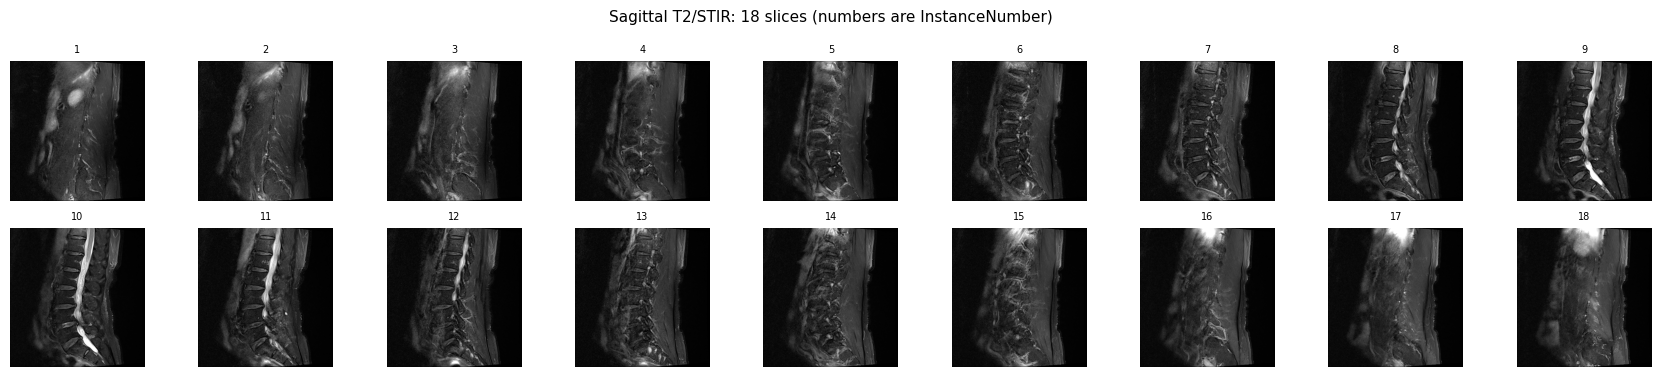

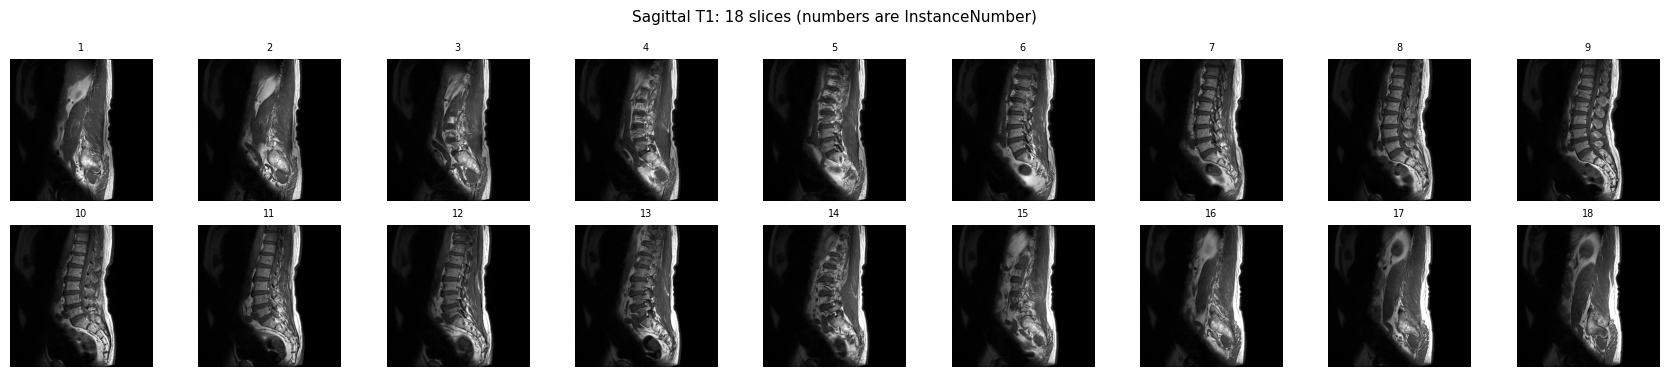

In [13]:
def contact_sheet(name, cols=10, size=1.3):
    "Show every slice in a series as small thumbnails labelled with InstanceNumber."
    slices = series[name]
    rows = int(np.ceil(len(slices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size))
    for ax in axes.flat:
        ax.axis("off")
    for ax, ds in zip(axes.flat, slices):
        ax.imshow(to_display(ds), cmap="gray")
        ax.set_title(int(ds.InstanceNumber), fontsize=7)
    fig.suptitle(f"{name}: {len(slices)} slices (numbers are InstanceNumber)", fontsize=11)
    plt.tight_layout()
    plt.show()


contact_sheet("Sagittal T2/STIR", cols=9, size=1.9)
contact_sheet("Sagittal T1", cols=9, size=1.9)

In the sagittal T2/STIR series, bright CSF fills the canal behind the discs in the middle slices (around 8–11). The outer slices pass through the foramina and muscles at the sides. In the sagittal T1 series, fat is bright; around the foramina it outlines the exiting nerve roots.

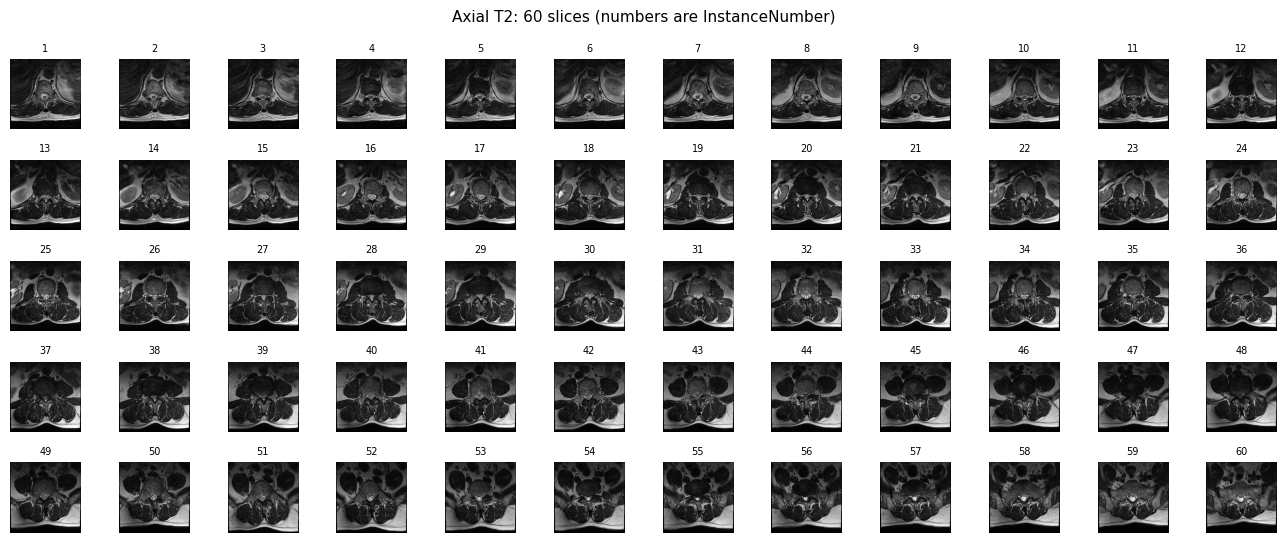

In [14]:
contact_sheet("Axial T2", cols=12, size=1.1)

Scroll from instance 1 (highest) downwards. The bright CSF circle of the thecal sac sits behind the round vertebral body or disc. Slices at disc levels look different from slices through the bone.

### Window/level comparison

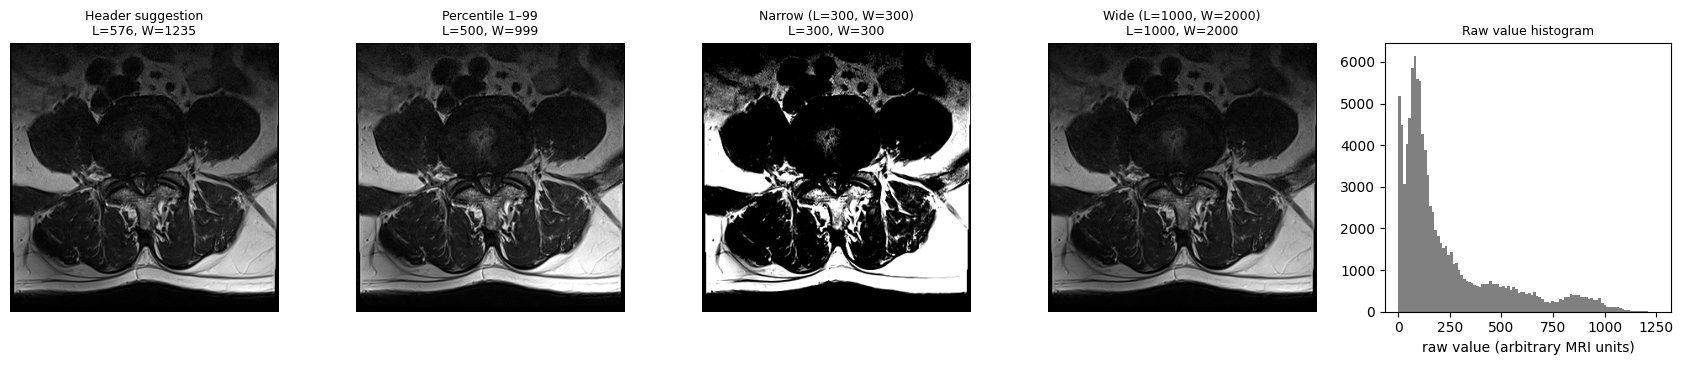

In [15]:
demo = series["Axial T2"][45]          # InstanceNumber 46, the L4/L5 annotation slice
pixels = raw_pixels(demo)
settings = [
    ("Header suggestion", *header_window(demo)),
    ("Percentile 1–99", *percentile_window(pixels)),
    ("Narrow (L=300, W=300)", 300, 300),
    ("Wide (L=1000, W=2000)", 1000, 2000),
]
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
for ax, (label, level, width) in zip(axes, settings):
    ax.imshow(apply_window(pixels, level, width), cmap="gray")
    ax.set_title(f"{label}\nL={level:.0f}, W={width:.0f}", fontsize=9)
    ax.axis("off")
axes[-1].hist(pixels.ravel(), bins=100, color="grey")
axes[-1].set_title("Raw value histogram", fontsize=9)
axes[-1].set_xlabel("raw value (arbitrary MRI units)")
plt.tight_layout()
plt.show()

Most pixels are dark background or soft tissue, while CSF and fat are a small bright tail. The narrow window turns everything above 450 white and hides the detail inside the CSF. The wide window flattens the contrast. **The pixels did not change, only how we look at them**, and the 8-bit image we send to a model inherits whichever choice we make.

### Expert annotations

Each row of `df_coords` is a point (x, y in pixels) that the annotator placed on a particular slice to show **where** they graded a condition at a level. We overlay them, coloured by the reference grade.

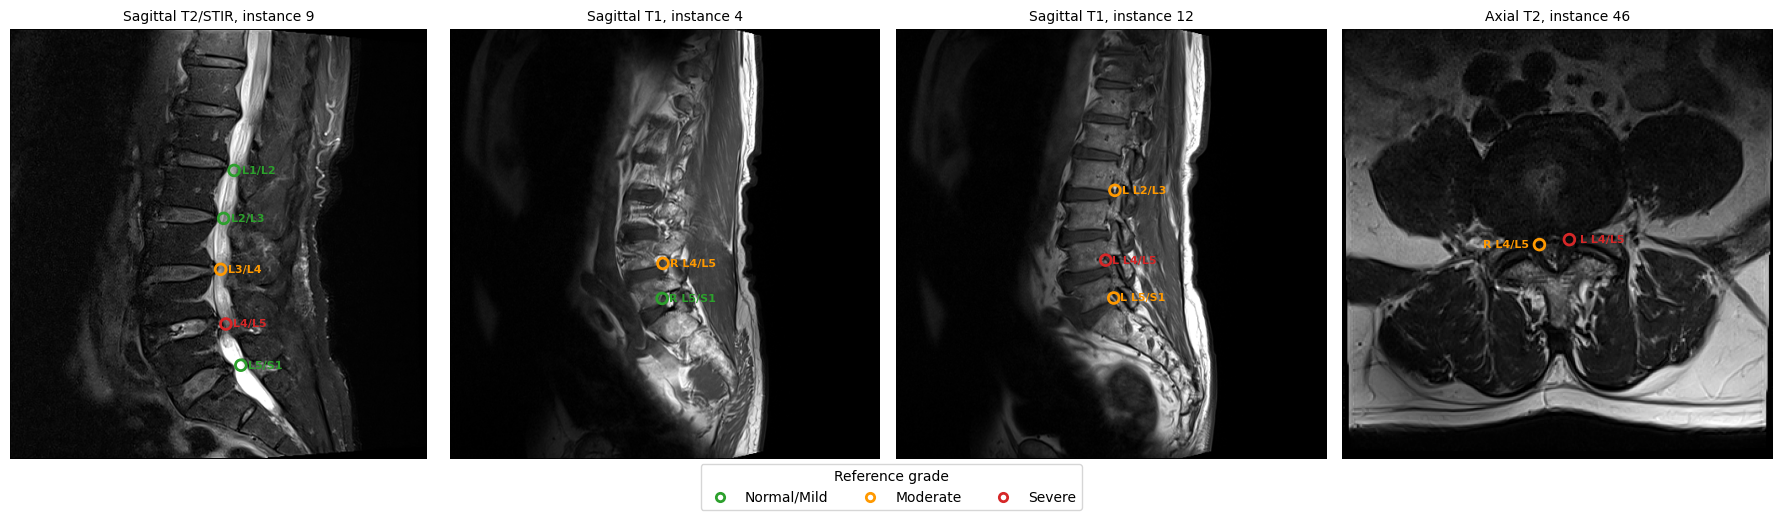

In [16]:
GRADE_COLOURS = {"Normal/Mild": "#2ca02c", "Moderate": "#ff9900", "Severe": "#d62728"}

coords = df_coords.copy()
coords["condition_key"] = coords["condition"].str.lower().str.replace(" ", "_")
coords = coords.merge(truth, left_on=["condition_key", "level"], right_on=["condition", "level"],
                      how="left", validate="one_to_one", suffixes=("", "_truth"))
assert coords["grade_true"].notna().all()   # every annotation point has a reference grade

DESCRIPTION_OF = {v: k for k, v in series_id_of.items()}


def annotated_instance(condition_key) -> tuple:
    "Return (series name, InstanceNumber) holding the most annotation points for a condition."
    rows = coords[coords["condition_key"] == condition_key]
    instance = int(rows.groupby("instance_number").size().idxmax())
    return DESCRIPTION_OF[int(rows["series_id"].iloc[0])], instance


def get_slice(series_name, instance):
    return next(ds for ds in series[series_name] if int(ds.InstanceNumber) == instance)


def show_annotations(ax, series_name, instance):
    ds = get_slice(series_name, instance)
    ax.imshow(to_display(ds), cmap="gray")
    points = coords[(coords["series_id"] == series_id_of[series_name]) &
                    (coords["instance_number"] == instance)]
    for p in points.itertuples():
        ax.scatter(p.x, p.y, s=60, facecolors="none", edgecolors=GRADE_COLOURS[p.grade_true], linewidths=2)
        side = "L " if p.condition_key.startswith("left") else "R " if p.condition_key.startswith("right") else ""
        # On axial slices the patient's right is on the image left, so put right-side labels on the left.
        right_on_axial = side == "R " and series_name.startswith("Axial")
        ax.text(p.x - 8 if right_on_axial else p.x + 8, p.y, f"{side}{p.level}", color=GRADE_COLOURS[p.grade_true],
                fontsize=8, fontweight="bold", va="center", ha="right" if right_on_axial else "left")
    ax.set_title(f"{series_name}, instance {instance}", fontsize=10)
    ax.axis("off")


panels = [annotated_instance("spinal_canal_stenosis"),
          annotated_instance("right_neural_foraminal_narrowing"),
          annotated_instance("left_neural_foraminal_narrowing"),
          ("Axial T2", 46)]
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (name, instance) in zip(axes, panels):
    show_annotations(ax, name, instance)
handles = [plt.Line2D([], [], marker="o", ls="", mfc="none", mec=c, mew=2, label=g) for g, c in GRADE_COLOURS.items()]
fig.legend(handles=handles, loc="lower center", ncol=3, title="Reference grade")
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

- **Panel 1 (sagittal T2, midline):** the five canal points run down the CSF column behind each disc. L4/L5 is graded Severe, and the bright CSF there is visibly thinner.
- **Panels 2–3 (sagittal T1):** the foraminal points sit in the foramina on the right side (instance 4) and the left side (instance 12), confirming the left/right geometry from B2. Not every level's point lies on the same slice.
- **Panel 4 (axial T2, L4/L5):** the left subarticular point (Severe) is on the **image right**, as the radiological convention predicts.

### ✏️ Exercise 3 — Look before you prompt

Before asking a model to grade images, look at what it will receive. You do not need to diagnose anything: each question asks you to compare what you see with the reference grades.

**Reminder.** On T2-weighted images, fluid is bright (section 2). In an axial slice, the spinal canal appears as a bright, roughly round patch of **cerebrospinal fluid (CSF)** just behind the disc or vertebral body, with the nerve roots floating in it (section 1.2). When the canal narrows, less bright fluid is left; radiologists describe this as a **crowded** or **compressed** thecal sac.

The starter cell below draws the images for Q1 and Q2. Run it, then answer in words.

1. **Compare the five levels.** The first row shows the axial annotation slice for each level, zoomed in on the canal, with the reference canal grade in each title. At which level is the bright CSF patch smallest or hardest to see? Does that match the level with the worst reference canal grade?
2. **Choose a window.** The second row shows the midline sagittal T2 slice with the header window and with the percentile window (section 5).
   - Which shows the discs and the bright CSF behind them more clearly?
   - Which setting is the same for every slice in the series, and which changes from slice to slice?
   - Which would you send to a model, and why? There is no single right answer: justify your choice.
3. **What is missing from one slice?** In E1 and E2 the model receives single 2D slices. In two or three sentences, name two things a radiologist reading the full study can use that one slice cannot provide. *Hint: think about the other slices, the other series, adjusting the window, and information that is not in the images at all.*

In [ ]:
# Exercise 3 — starter code. Run it, then answer the questions above.

# Q1: the axial annotation slice for each level, zoomed in on the canal.
AXIAL_SLICE_OF = {"L1/L2": 20, "L2/L3": 28, "L3/L4": 37, "L4/L5": 46, "L5/S1": 55}
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, (level, instance) in zip(axes, AXIAL_SLICE_OF.items()):
    show_annotations(ax, "Axial T2", instance)
    ax.set_xlim(80, 240)   # zoom to columns 80-240 ...
    ax.set_ylim(250, 90)   # ... and rows 90-250 (larger value first, so the image is not flipped)
    canal_grade = truth_grid.loc["spinal_canal_stenosis", level]
    ax.set_title(f"{level} (instance {instance})\nreference canal grade: {canal_grade}", fontsize=9)
plt.tight_layout()
plt.show()

# Q2: the same midline sagittal slice with two windows.
name, instance = annotated_instance("spinal_canal_stenosis")
ds = get_slice(name, instance)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, method in zip(axes, ["header", "percentile"]):
    ax.imshow(to_display(ds, method), cmap="gray")
    ax.set_title(f"{name}, instance {instance}: {method} window", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## B4. Asking MedGemma

### The client and the response store

`ask_medgemma` either calls the live model (`RUN_MODEL = True`) or returns the saved response for the same experiment ID. Every live response is stored with the prompt, settings, model information, and a SHA-256 hash of each image sent. When reading saved responses, the notebook recomputes the image hashes. If they match, you know the saved answer was produced from exactly the images you are looking at.

All prompts use temperature 0 (least random decoding) unless stated. Even then, outputs can differ across software versions and hardware.

In [18]:
def png_bytes(image: Image.Image) -> bytes:
    buffer = io.BytesIO()
    image.save(buffer, format="PNG")
    return buffer.getvalue()


def slice_image(ds) -> Image.Image:
    "The exact picture sent to the model: header window, 8-bit, RGB PNG."
    return Image.fromarray(to_display(ds, "header")).convert("RGB")


RUN_RECORDS = {}
RUN_FILE = None
CACHED = {}

if RUN_MODEL:
    import requests
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    RUN_FILE = RUN_DIR / f"run-{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}.json"
    assert not RUN_FILE.exists()
    # Best-effort model details (LM Studio's own REST API reports quantization).
    try:
        info = requests.get(LM_STUDIO_BASE_URL.replace("/v1", "/api/v0") + f"/models/{MODEL_ID}", timeout=10).json()
        MODEL_INFO = {k: info.get(k) for k in ("id", "arch", "quantization", "compatibility_type", "max_context_length")}
    except Exception as error:
        MODEL_INFO = {"id": MODEL_ID, "note": f"details unavailable: {error}"}
    print("Live run; responses will be saved to", RUN_FILE)
    print("Model:", MODEL_INFO)
else:
    run_files = sorted(RUN_DIR.glob("run-*.json"))
    source = CACHE_FILE or (run_files[-1] if run_files else None)
    if source is None:
        print(f"No saved runs in {RUN_DIR}. Set RUN_MODEL = True with LM Studio running, or ask your instructor.")
    else:
        saved = json.loads(Path(source).read_text())
        CACHED = saved["records"]
        MODEL_INFO = saved["model_info"]
        print("Using saved responses from", source.name)
        print("Created (UTC):", saved["created_utc"], "| model:", MODEL_INFO)


def ask_medgemma(run_id, prompt, images, temperature=0.0, seed=0, max_tokens=400):
    "Return MedGemma's reply text for one experiment, live or from the saved run."
    pngs = [png_bytes(image) for image in images]
    hashes = [hashlib.sha256(p).hexdigest() for p in pngs]
    if not RUN_MODEL:
        record = CACHED.get(run_id)
        if record is None:
            return f"[no saved response for {run_id}]"
        if record["image_sha256"] != hashes:
            print(f"⚠ {run_id}: images differ from those used for the saved response")
        return record["response"]

    content = [{"type": "text", "text": prompt}]
    content += [{"type": "image_url", "image_url": {"url": "data:image/png;base64," + base64.b64encode(p).decode()}}
                for p in pngs]
    payload = {"model": MODEL_ID, "messages": [{"role": "user", "content": content}],
               "temperature": temperature, "seed": seed, "max_tokens": max_tokens}
    start = time.time()
    reply = requests.post(f"{LM_STUDIO_BASE_URL}/chat/completions", json=payload, timeout=900)
    reply.raise_for_status()
    text = reply.json()["choices"][0]["message"]["content"]
    RUN_RECORDS[run_id] = {"prompt": prompt, "image_sha256": hashes, "temperature": temperature,
                           "seed": seed, "max_tokens": max_tokens, "seconds": round(time.time() - start, 1),
                           "response": text}
    RUN_FILE.write_text(json.dumps({"created_utc": datetime.now(timezone.utc).isoformat(),
                                    "server": "LM Studio OpenAI-compatible API", "model_info": MODEL_INFO,
                                    "study_id": STUDY_ID, "records": RUN_RECORDS}, indent=2))
    return text

Using saved responses from run-20261009T082446Z.json
Created (UTC): 2026-10-09T08:26:33.595068+00:00 | model: {'id': 'medgemma-1.5-4b-it', 'arch': 'gemma3', 'quantization': 'Q4_K_S', 'compatibility_type': 'gguf', 'max_context_length': 131072}


### Parsing replies into labels

We ask for JSON, but a generative model may add text around it, wrap it in a code fence, or use its own words for grades. The **normalization policy** below is fixed **before** looking at any results, so that we cannot bend the scoring to suit the model:

| Model wrote (ignoring case) | Scored as |
|---|---|
| `normal/mild`, `normal`, `mild`, `none` | Normal/Mild (the dataset merges normal and mild) |
| `moderate` | Moderate |
| `severe` | Severe |
| `cannot assess` | Cannot assess (allowed, but not a grade) |
| anything else, or a missing key | Invalid |

In [19]:
GRADE_SYNONYMS = {"normal/mild": "Normal/Mild", "normal": "Normal/Mild", "mild": "Normal/Mild",
                  "none": "Normal/Mild", "moderate": "Moderate", "severe": "Severe",
                  "cannot assess": "Cannot assess"}


def extract_json(text):
    "Return the JSON object in a reply (fences and extra text ignored), or None if it is not valid JSON."
    cleaned = re.sub(r"```(?:json)?", "", text)
    start, end = cleaned.find("{"), cleaned.rfind("}")
    if start == -1 or end <= start:
        return None
    try:
        return json.loads(cleaned[start:end + 1])
    except json.JSONDecodeError:
        return None


def normalize_grade(value):
    if not isinstance(value, str):
        return "Invalid"
    return GRADE_SYNONYMS.get(value.strip().lower(), "Invalid")


print(normalize_grade("Mild"), "|", normalize_grade("mild to moderate"), "|", extract_json('```json\n{"a": 1}\n```'))

Normal/Mild | Invalid | {'a': 1}


### ✏️ Exercise 4 — Predict before you look

Before reading any model output, write down your predictions. Writing them first prevents **hindsight bias**: once you have seen a result, it is easy to believe you expected it. Any prediction earns credit if the reason is sensible.

A reminder of what the two main experiments send (section 7.1):

| | E1 naive | E2 expert-guided |
|---|---|---|
| Images per request | 3: the middle slice of each series | 1: the slice the expert annotated |
| Questions per request | All 25 labels at once | One condition (five levels, or left and right at one level) |
| Can the images show every structure asked about? | No. For example, the middle sagittal slices do not pass through the foramina at the sides | Mostly |

For each question, choose an option and add one sentence of reasoning.

1. Which will agree better with the reference grades? **(a)** E1, **(b)** E2, or **(c)** about the same.
2. The baseline "always Normal/Mild" is correct exactly as often as this patient has Normal/Mild labels (your count from Exercise 1, out of 25). Will E2 beat this baseline: **(a)** yes, clearly, **(b)** about the same, or **(c)** no? Would beating it be strong evidence that the model reads the image?
3. We send a completely black image with the spinal canal prompt, which allows "Cannot assess". What *should* a trustworthy model answer? What do you expect *this* model to answer?

*Your answers:*

### E0 — Sanity check: what is this image?

The DICOM geometry already tells us each plane. If the model cannot identify the plane, its detailed grading is unlikely to be meaningful.

In [20]:
E0_PROMPT = ("This is an educational evaluation of an AI model on a de-identified research image; it is not patient care.\n"
             "Identify the image. Return only JSON with no other text:\n"
             '{"modality": "...", "body_region": "...", "plane": "axial | sagittal | coronal"}')

e0_rows = []
for name in ["Sagittal T2/STIR", "Sagittal T1", "Axial T2"]:
    ds = series[name][len(series[name]) // 2]
    reply = ask_medgemma(f"E0_{name}", E0_PROMPT, [slice_image(ds)], max_tokens=80)
    parsed = extract_json(reply) or {}
    e0_rows.append({"series": name, "plane from DICOM": slice_plane(ds),
                    "model modality": parsed.get("modality"), "model region": parsed.get("body_region"),
                    "model plane": parsed.get("plane"), "raw reply": reply.strip()[:120]})
display(pd.DataFrame(e0_rows))

,series,plane from DICOM,model modality,model region,model plane,raw reply
0,Sagittal T2/STIR,sagittal,MRI,Spine,sagittal,"```json\n{""modality"": ""MRI"", ""body_region"": ""S..."
1,Sagittal T1,sagittal,MRI,spine,sagittal,"```json\n{""modality"": ""MRI"", ""body_region"": ""s..."
2,Axial T2,axial,MRI,spine,axial,"```json\n{""modality"": ""MRI"", ""body_region"": ""s..."


### E1 — Naive whole-study prompt

This mirrors a typical first attempt: take the middle slice of each series, send all three images in one request, and ask for all 25 grades. Note that the model card says MedGemma has **not been evaluated on multiple-image comprehension**.

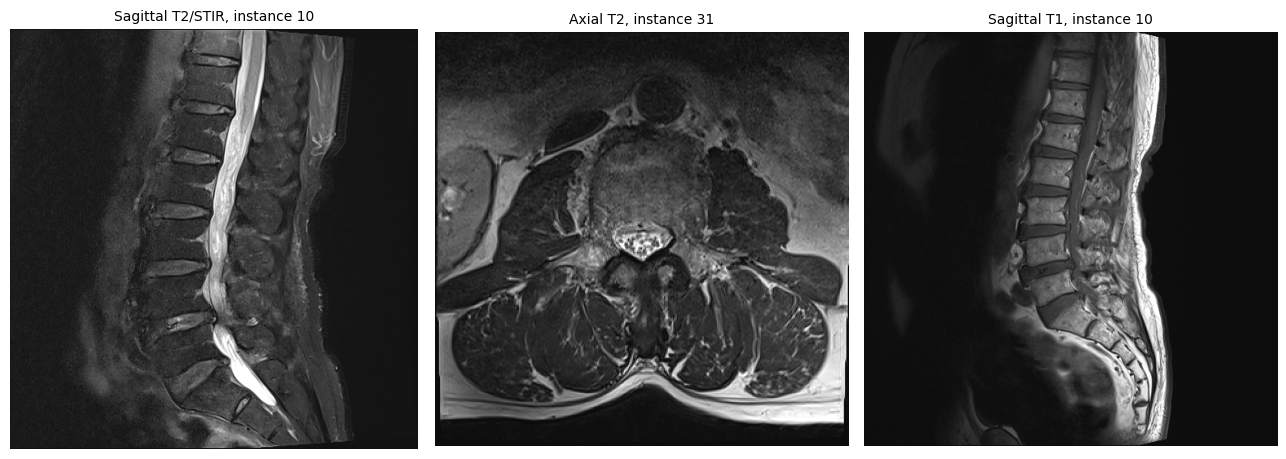

caution: this is an educational evaluation of an AI model on de-identified research images; it is not patient care.
```json
{
"spinal_canal_stenosis": {
"L1/L2": "Normal/Mild",
"L2/L3": "Normal/Mild",
"L3/L4": "Moderate",
"L4/L5": "Severe",
"L5/S1": "Normal/Mild"
},
"left_neural_foraminal_narrowing": {
"L1/L2": "Normal/Mild",
"L2/L3": "Normal/Mild",
"L3/L4": "Moderate",
"L4/L5": "Severe",
"L5/S1": "Normal/Mild"
},
"right_neural_foraminal_narrowing": {
"L1/L2": "Normal/Mild",
"L2/L3": "Normal/Mild",
"L3/L4": "Moderate",
"L4/L5": "Severe",
"L5/S1": "Normal/Mild"
},
"left_subarticular_stenosis": {
"L1/L2": "Cannot assess",
"L2/L3": "Cannot assess",
"L3/L4": "Moderate",
"L4/L5": "Severe",
"L5/S1": "Cannot assess"
},
"right_subarticular_stenosis": {
"L1/L2": "Cannot assess",
"L2/L3": "Cannot assess",
"L3/L4": "Moderate",
"L4/L5": "Severe",
"L5/S1": "Cannot assess"
}
}
```


In [21]:
E1_SLICES = {name: series[name][len(series[name]) // 2] for name in ["Sagittal T2/STIR", "Axial T2", "Sagittal T1"]}

E1_PROMPT = '''This is an educational evaluation of an AI model on de-identified research images; it is not patient care.
You are given three lumbar spine MRI images from one study, in this order:
Image 1: sagittal T2/STIR. Image 2: axial T2. Image 3: sagittal T1.
Grade each condition at each intervertebral disc level from L1/L2 to L5/S1.
Allowed grades: "Normal/Mild", "Moderate", "Severe", or "Cannot assess" (use it if the level or structure is not visible).
Return only JSON with no other text, using exactly these keys:
{"spinal_canal_stenosis": {"L1/L2": "", "L2/L3": "", "L3/L4": "", "L4/L5": "", "L5/S1": ""},
 "left_neural_foraminal_narrowing": {...same five levels...},
 "right_neural_foraminal_narrowing": {...},
 "left_subarticular_stenosis": {...},
 "right_subarticular_stenosis": {...}}'''

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, (name, ds) in zip(axes, E1_SLICES.items()):
    ax.imshow(slice_image(ds))
    ax.set_title(f"{name}, instance {int(ds.InstanceNumber)}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

e1_reply = ask_medgemma("E1_naive_multiseries", E1_PROMPT, [slice_image(ds) for ds in E1_SLICES.values()], max_tokens=700)
print(e1_reply)

In [22]:
def labels_from_nested(parsed) -> pd.DataFrame:
    "Turn {condition: {level: grade}} into one normalized row per label (25 rows)."
    rows = []
    for condition in CONDITIONS:
        block = parsed.get(condition, {}) if isinstance(parsed, dict) else {}
        block = block if isinstance(block, dict) else {}
        for level in LEVELS:
            rows.append({"condition": condition, "level": level, "grade_pred": normalize_grade(block.get(level))})
    return pd.DataFrame(rows)


e1_labels = labels_from_nested(extract_json(e1_reply))
print("Parsed as JSON:", extract_json(e1_reply) is not None)
print(e1_labels["grade_pred"].value_counts().to_string())

Parsed as JSON: True
grade_pred
Normal/Mild      9
Cannot assess    6
Moderate         5
Severe           5


The axial middle slice (instance 31) comes from one tilted block and shows one cross-section; in this study it passes through a vertebral body, not a disc. It cannot show all five levels, and the sagittal middle slices cannot show the left and right foramina. So most of the 25 answers **cannot be grounded in the supplied pixels**, whatever the model writes. Notice whether the model admits this with "Cannot assess".

### E2 — Expert-guided prompts

Now we give the model its best chance: the slice the expert used, the right sequence, a description of the view, and a narrow question. Remember the warning in section 7.1: choosing these slices used the reference annotations.

In [23]:
PREAMBLE = "This is an educational evaluation of an AI model on a de-identified research image; it is not patient care.\n"
GRADE_RULES = ('Allowed grades: "Normal/Mild", "Moderate", "Severe", or "Cannot assess" '
               '(use it if the structure is not visible or you cannot identify the level).\n'
               "Return only JSON with no other text.")
LEVEL_JSON = '{"L1/L2": "", "L2/L3": "", "L3/L4": "", "L4/L5": "", "L5/S1": ""}'

e2_requests = []   # (run_id, prompt, slice, how to turn the parsed JSON into labels)

# Spinal canal: midline sagittal T2.
name, instance = annotated_instance("spinal_canal_stenosis")
e2_requests.append(("E2_canal", PREAMBLE +
    "Image: one midline sagittal T2-weighted MRI slice of the lumbar spine. Top = superior, image left = anterior.\n"
    "Task: grade SPINAL CANAL STENOSIS at each intervertebral disc level.\n" + GRADE_RULES + "\n" + LEVEL_JSON,
    get_slice(name, instance), lambda j: {("spinal_canal_stenosis", lv): j.get(lv) for lv in LEVELS}))

# Neural foramina: one parasagittal T1 slice per side.
for side in ["right", "left"]:
    name, instance = annotated_instance(f"{side}_neural_foraminal_narrowing")
    e2_requests.append((f"E2_foramen_{side}", PREAMBLE +
        f"Image: one parasagittal T1-weighted MRI slice through the patient's {side.upper()} lumbar neural foramina. "
        "Top = superior, image left = anterior.\n"
        f"Task: grade {side.upper()} NEURAL FORAMINAL NARROWING at each intervertebral disc level.\n"
        + GRADE_RULES + "\n" + LEVEL_JSON,
        get_slice(name, instance),
        lambda j, s=side: {(f"{s}_neural_foraminal_narrowing", lv): j.get(lv) for lv in LEVELS}))

# Subarticular zones: one axial T2 slice per level.
for level in LEVELS:
    rows = coords[(coords["condition_key"] == "left_subarticular_stenosis") & (coords["level"] == level)]
    instance = int(rows["instance_number"].iloc[0])
    e2_requests.append((f"E2_subarticular_{level}", PREAMBLE +
        f"Image: one axial T2-weighted MRI slice at approximately the {level} disc level of the lumbar spine, "
        "in radiological convention: the patient's LEFT is on the image RIGHT; top = anterior.\n"
        "Task: grade LEFT and RIGHT SUBARTICULAR (lateral recess) STENOSIS at this level.\n"
        + GRADE_RULES + '\n{"left": "", "right": ""}',
        get_slice("Axial T2", instance),
        lambda j, lv=level: {("left_subarticular_stenosis", lv): j.get("left"),
                             ("right_subarticular_stenosis", lv): j.get("right")}))

print(len(e2_requests), "requests; example prompt:\n")
print(e2_requests[0][1])

8 requests; example prompt:

This is an educational evaluation of an AI model on a de-identified research image; it is not patient care.
Image: one midline sagittal T2-weighted MRI slice of the lumbar spine. Top = superior, image left = anterior.
Task: grade SPINAL CANAL STENOSIS at each intervertebral disc level.
Allowed grades: "Normal/Mild", "Moderate", "Severe", or "Cannot assess" (use it if the structure is not visible or you cannot identify the level).
Return only JSON with no other text.
{"L1/L2": "", "L2/L3": "", "L3/L4": "", "L4/L5": "", "L5/S1": ""}


In [24]:
e2_rows, e2_raw = [], {}
for run_id, prompt, ds, to_labels in e2_requests:
    reply = ask_medgemma(run_id, prompt, [slice_image(ds)], max_tokens=150)
    e2_raw[run_id] = reply
    parsed = extract_json(reply)
    mapping = to_labels(parsed) if isinstance(parsed, dict) else {}
    for (condition, level), value in mapping.items():
        e2_rows.append({"condition": condition, "level": level, "grade_pred": normalize_grade(value)})

e2_labels = (pd.DataFrame(e2_rows, columns=["condition", "level", "grade_pred"])
             .set_index(["condition", "level"])
             .reindex(pd.MultiIndex.from_product([CONDITIONS, LEVELS], names=["condition", "level"]),
                      fill_value="Invalid")        # an unparseable reply leaves its labels Invalid
             .reset_index())
for run_id, reply in e2_raw.items():
    print(f"{run_id:28s} {reply.strip()[:110]!r}")

E2_canal                     '```json\n{"L1/L2": "Normal/Mild", "L2/L3": "Normal/Mild", "L3/L4": "Moderate", "L4/L5": "Severe", "L5/S1": "Sev'
E2_foramen_right             '```json\n{"L1/L2": "Normal/Mild", "L2/L3": "Moderate", "L3/L4": "Severe", "L4/L5": "Severe", "L5/S1": "Severe"}'
E2_foramen_left              '{"L1/L2": "Normal/Mild", "L2/L3": "Moderate", "L3/L4": "Severe", "L4/L5": "Severe", "L5/S1": "Severe"}'
E2_subarticular_L1/L2        '```json\n{"left": "Normal/Mild", "right": "Normal/Mild"}\n```'
E2_subarticular_L2/L3        '```json\n{"left": "Normal/Mild", "right": "Normal/Mild"}\n```'
E2_subarticular_L3/L4        '```json\n{"left": "Moderate", "right": "Normal/Mild"}\n```'
E2_subarticular_L4/L5        '```json\n{"left": "Moderate", "right": "Moderate"}\n```'
E2_subarticular_L5/S1        '```json\n{"left": "Moderate", "right": "Normal/Mild"}\n```'


## B5. Scoring against the reference standard

We join predictions to the reference on `(condition, level)`. `validate="one_to_one"` makes pandas raise an error if either table has duplicate keys, so the joined table must have exactly 25 rows, one per label.

In [25]:
baseline_labels = truth[["condition", "level"]].assign(grade_pred="Normal/Mild")

APPROACHES = {"Baseline: always Normal/Mild": baseline_labels,
              "E1 naive multi-series": e1_labels,
              "E2 expert-guided": e2_labels}


def join_with_truth(labels):
    merged = truth.merge(labels, on=["condition", "level"], how="left", validate="one_to_one")
    assert len(merged) == 25 and merged["grade_pred"].notna().all()
    return merged


def ratio(numerator, denominator):
    return f"{numerator}/{denominator} ({numerator / denominator:.0%})" if denominator else f"{numerator}/0 (undefined)"


def score(labels) -> dict:
    m = join_with_truth(labels)
    graded = m["grade_pred"].isin(GRADES)
    ref_pos = m["grade_true"].isin(["Moderate", "Severe"])
    pred_pos = m["grade_pred"].isin(["Moderate", "Severe"])
    tp = int((graded & ref_pos & pred_pos).sum())
    fn = int((graded & ref_pos & ~pred_pos).sum())
    fp = int((graded & ~ref_pos & pred_pos).sum())
    tn = int((graded & ~ref_pos & ~pred_pos).sum())
    return {"graded (format OK)": ratio(int(graded.sum()), 25),
            "Cannot assess": int((m["grade_pred"] == "Cannot assess").sum()),
            "Invalid": int((m["grade_pred"] == "Invalid").sum()),
            "exact agreement (of 25)": ratio(int((m["grade_pred"] == m["grade_true"]).sum()), 25),
            "sensitivity (high grade)": ratio(tp, tp + fn),
            "specificity": ratio(tn, tn + fp),
            "PPV": ratio(tp, tp + fp),
            "NPV": ratio(tn, tn + fn)}


display(pd.DataFrame({name: score(labels) for name, labels in APPROACHES.items()}))

,Baseline: always Normal/Mild,E1 naive multi-series,E2 expert-guided
graded (format OK),25/25 (100%),19/25 (76%),25/25 (100%)
Cannot assess,0,6,0
Invalid,0,0,0
exact agreement (of 25),9/25 (36%),12/25 (48%),16/25 (64%)
sensitivity (high grade),0/16 (0%),10/14 (71%),13/16 (81%)
specificity,9/9 (100%),5/5 (100%),7/9 (78%)
PPV,0/0 (undefined),10/10 (100%),13/15 (87%)
NPV,9/25 (36%),5/9 (56%),7/10 (70%)


In [26]:
def grid_of(labels):
    return labels.pivot(index="condition", columns="level", values="grade_pred").loc[CONDITIONS, LEVELS]

for title, grid in [("Reference", truth_grid), ("E1 naive multi-series", grid_of(e1_labels)),
                    ("E2 expert-guided", grid_of(e2_labels))]:
    display(Markdown(f"**{title}**"))
    display(style_grades(grid))

**Reference**

level,L1/L2,L2/L3,L3/L4,L4/L5,L5/S1
condition,,,,,
spinal_canal_stenosis,Normal/Mild,Normal/Mild,Moderate,Severe,Normal/Mild
left_neural_foraminal_narrowing,Normal/Mild,Moderate,Moderate,Severe,Moderate
right_neural_foraminal_narrowing,Moderate,Moderate,Severe,Moderate,Normal/Mild
left_subarticular_stenosis,Normal/Mild,Normal/Mild,Moderate,Severe,Moderate
right_subarticular_stenosis,Normal/Mild,Normal/Mild,Moderate,Moderate,Moderate


**E1 naive multi-series**

level,L1/L2,L2/L3,L3/L4,L4/L5,L5/S1
condition,,,,,
spinal_canal_stenosis,Normal/Mild,Normal/Mild,Moderate,Severe,Normal/Mild
left_neural_foraminal_narrowing,Normal/Mild,Normal/Mild,Moderate,Severe,Normal/Mild
right_neural_foraminal_narrowing,Normal/Mild,Normal/Mild,Moderate,Severe,Normal/Mild
left_subarticular_stenosis,Cannot assess,Cannot assess,Moderate,Severe,Cannot assess
right_subarticular_stenosis,Cannot assess,Cannot assess,Moderate,Severe,Cannot assess


**E2 expert-guided**

level,L1/L2,L2/L3,L3/L4,L4/L5,L5/S1
condition,,,,,
spinal_canal_stenosis,Normal/Mild,Normal/Mild,Moderate,Severe,Severe
left_neural_foraminal_narrowing,Normal/Mild,Moderate,Severe,Severe,Severe
right_neural_foraminal_narrowing,Normal/Mild,Moderate,Severe,Severe,Severe
left_subarticular_stenosis,Normal/Mild,Normal/Mild,Moderate,Moderate,Moderate
right_subarticular_stenosis,Normal/Mild,Normal/Mild,Normal/Mild,Moderate,Normal/Mild


In [27]:
# Confusion tables: rows = reference grade, columns = model output.
for name in ["E1 naive multi-series", "E2 expert-guided"]:
    merged = join_with_truth(APPROACHES[name])
    table = pd.crosstab(pd.Categorical(merged["grade_true"], GRADES),
                        pd.Categorical(merged["grade_pred"], GRADES + ["Cannot assess", "Invalid"]),
                        rownames=["reference"], colnames=["model"], dropna=False)
    display(Markdown(f"**{name}**"))
    display(table)

**E1 naive multi-series**

model,Normal/Mild,Moderate,Severe,Cannot assess,Invalid
reference,,,,,
Normal/Mild,5,0,0,4,0
Moderate,4,4,2,2,0
Severe,0,1,3,0,0


**E2 expert-guided**

model,Normal/Mild,Moderate,Severe,Cannot assess,Invalid
reference,,,,,
Normal/Mild,7,0,2,0,0
Moderate,3,6,3,0,0
Severe,0,1,3,0,0


### How to read these tables

- Compare each approach with the **baseline**, not with 0%. This patient has many Moderate and Severe labels, so the baseline's agreement is low and its sensitivity is zero by construction. On a typical patient from this dataset, where most labels are Normal/Mild, the same baseline would look much better.
- Check **which** errors occur. A Severe site called Normal/Mild (a false negative) has different consequences from a Normal/Mild site called Moderate (a false positive).
- Check the **denominators**. Sensitivity and PPV are computed only on labels that received a grade. A model that answers "Cannot assess" often may score well on what it graded, but covers little.
- Every number here comes from **one patient, one annotator, and one run**. It is a description, not an estimate of performance.

### ✏️ Exercise 5 — Interpret the scores

1. Compare your Exercise 4 predictions with the results. Which surprised you?
2. Find one label where E2 disagrees with the reference by **two** grades (Normal/Mild ↔ Severe), or explain why there is none. Look at that slice again with `show_annotations`. Can you see why either the model or the annotator might be wrong?
3. Did E1 use "Cannot assess" for labels that its three images could not show (for example, the foramina)? What does it mean when a model grades structures that are not in its input?
4. Compare E1's grade pattern across the five conditions, row by row. What do you notice, and what does it suggest about how the grades were produced?
5. Write one sentence that a news headline might wrongly conclude from these tables, and one sentence that the tables actually support.

In [28]:
# Exercise 5 — your code here

## B6. Stress tests

A trustworthy system should be stable when nothing changes, refuse to answer when there is no evidence, and change its answer when the evidence changes. We test all three on the spinal canal and L4/L5 subarticular prompts from E2.

### E3a — Repeat sampling

We send the same canal prompt three more times with temperature 0.7 and different seeds. Clinical grading should not depend on random sampling.

In [29]:
canal_run_id, canal_prompt, canal_slice, canal_to_labels = e2_requests[0]
repeat_rows = {"E2 (temperature 0)": {lv: normalize_grade((extract_json(e2_raw[canal_run_id]) or {}).get(lv)) for lv in LEVELS}}
for seed in [1, 2, 3]:
    reply = ask_medgemma(f"E3_repeat_canal_seed{seed}", canal_prompt, [slice_image(canal_slice)],
                         temperature=0.7, seed=seed, max_tokens=150)
    parsed = extract_json(reply) or {}
    repeat_rows[f"temperature 0.7, seed {seed}"] = {lv: normalize_grade(parsed.get(lv)) for lv in LEVELS}

repeats = pd.DataFrame(repeat_rows).T
repeats.loc["Reference"] = truth_grid.loc["spinal_canal_stenosis"]
display(style_grades(repeats))
unstable = [lv for lv in LEVELS if repeats.loc[repeats.index != "Reference", lv].nunique() > 1]
print("Levels whose grade changed between runs:", unstable or "none")

,L1/L2,L2/L3,L3/L4,L4/L5,L5/S1
E2 (temperature 0),Normal/Mild,Normal/Mild,Moderate,Severe,Severe
"temperature 0.7, seed 1",Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
"temperature 0.7, seed 2",Normal/Mild,Normal/Mild,Moderate,Moderate,Moderate
"temperature 0.7, seed 3",Normal/Mild,Normal/Mild,Moderate,Severe,Severe
Reference,Normal/Mild,Normal/Mild,Moderate,Severe,Normal/Mild


Levels whose grade changed between runs: ['L3/L4', 'L4/L5', 'L5/S1']


### E3b — Blank image

A black image with the canal prompt. The prompt allows "Cannot assess". Any grade other than "Cannot assess" is an answer with no image evidence behind it.

In [30]:
blank = Image.new("RGB", slice_image(canal_slice).size, (0, 0, 0))
blank_reply = ask_medgemma("E3_blank_canal", canal_prompt, [blank], max_tokens=150)
print(blank_reply)
blank_parsed = extract_json(blank_reply) or {}
print("Normalized:", {lv: normalize_grade(blank_parsed.get(lv)) for lv in LEVELS})

```json
{"L1/L2": "Normal/Mild", "L2/L3": "Moderate", "L3/L4": "Severe", "L4/L5": "Severe", "L5/S1": "Severe"}
```
Normalized: {'L1/L2': 'Normal/Mild', 'L2/L3': 'Moderate', 'L3/L4': 'Severe', 'L4/L5': 'Severe', 'L5/S1': 'Severe'}


### E3c — Mirrored image: does the model use left and right?

At L4/L5, the reference has **left Severe, right Moderate**. We mirror the axial slice left to right but keep the prompt unchanged, so it still claims that the patient's left is on the image right. If the model reads the image, its left and right grades should **swap**. If they stay the same, the model is not using the image to decide sides.

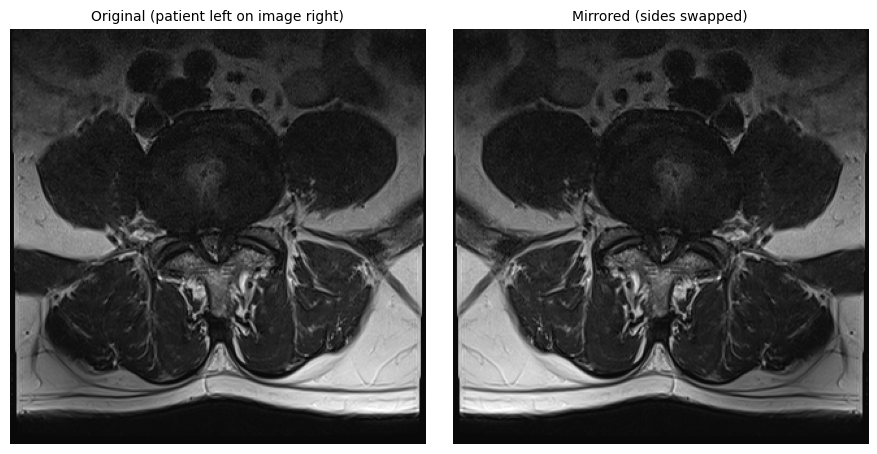

,left,right
Original,Moderate,Moderate
Mirrored,Moderate,Normal/Mild
Reference (original image),Severe,Moderate


In [31]:
l45_run_id, l45_prompt, l45_slice, _ = next(r for r in e2_requests if r[0] == "E2_subarticular_L4/L5")
original_img = slice_image(l45_slice)
mirrored_img = ImageOps.mirror(original_img)

mirror_reply = ask_medgemma("E3_mirror_subarticular_L4/L5", l45_prompt, [mirrored_img], max_tokens=150)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, img, title in [(axes[0], original_img, "Original (patient left on image right)"),
                       (axes[1], mirrored_img, "Mirrored (sides swapped)")]:
    ax.imshow(img)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

side_rows = {}
for label, reply in [("Original", e2_raw[l45_run_id]), ("Mirrored", mirror_reply)]:
    parsed = extract_json(reply) or {}
    side_rows[label] = {"left": normalize_grade(parsed.get("left")), "right": normalize_grade(parsed.get("right"))}
side_rows["Reference (original image)"] = {"left": truth_grid.loc["left_subarticular_stenosis", "L4/L5"],
                                           "right": truth_grid.loc["right_subarticular_stenosis", "L4/L5"]}
display(pd.DataFrame(side_rows).T)

### ✏️ Exercise 6 — What did the stress tests reveal?

1. For each test (E3a–c), state in one sentence what a trustworthy system should do and what this model did.
2. Compare the blank-image grades with the E2 neural foraminal grades for the right and left sides. What does the comparison suggest about where those E2 grades came from?
3. Look at the model's **original** L4/L5 left and right grades. Could the mirror test have shown a swap at this level? Which level would make a more informative mirror test, judging from the E2 subarticular replies, and why must that choice be made before seeing the mirrored result?
4. Propose one more stress test, for example sending a sagittal slice but describing it as axial, or sending a slice from a different level. Describe what result would worry you. (Optional: implement it if `RUN_MODEL = True`.)

In [32]:
# Exercise 6 — your code here (optional live experiment)

## B7. Reflection, deliverables, and rubric

### ✏️ Exercise 7 — Design a real evaluation

You are asked whether MedGemma could help radiologists grade lumbar stenosis at a hospital. In about 150 words, outline an evaluation that could support that decision. Include: the data (how many studies, from where, labelled how), how slices or volumes would be chosen **without** using the reference annotations, the metrics and baseline (including a task-specific model), and how a radiologist would review the output.

### Reflection (200–300 words)

Write a short memo to a hospital manager who has seen a demonstration in which MedGemma "correctly found the severe level". Using your results, explain what this notebook does and does not show, the most important failure mode you observed, and what you would need before trusting such a tool in a reporting workflow.

### Deliverables

1. This notebook, run from top to bottom in a fresh kernel, with your code for Exercises 1–3 and 5–6.
2. Written answers to Exercises 1–7.
3. The reflection memo.

### Rubric (20 points)

| Criterion | Excellent (4) | Adequate (2–3) | Weak (0–1) |
|---|---|---|---|
| **Data and units** (Ex. 1) | Correct counts; distinguishes study, slice, label, and annotation point | Mostly correct; some confusion of units | Counts wrong or units confused |
| **DICOM geometry and display** (Ex. 2–3) | Uses tags to verify sides, order, and distances; justifies the window choice | Correct code with thin explanation | Relies on file names or guesses |
| **Model experiment and parsing** (Ex. 4, B4) | Predictions written before results; explains how normalization and parsing affect scores | Runs the experiments; limited reflection | Treats raw text as results without parsing |
| **Evaluation and baseline** (Ex. 5–6) | Compares with the baseline; reads the denominators; explains the stress-test outcomes precisely | Reports metrics with partial interpretation | Reports accuracy only, or overclaims |
| **Limitations and communication** (Ex. 7, memo) | Clear, specific, and honest about one patient, one annotator, quantization, and clinical use | Generic limitations | Claims the model is ready for clinical use |

### Optional extensions

- **Crop the region of interest.** Crop a 40 × 40 mm square around each annotation point and repeat E2. Does a smaller field of view help? (Remember that crops also use the reference coordinates.)
- **Compare models.** If LM Studio also serves `medgemma-4b-it` (version 1), set `MODEL_ID` and rerun B4–B6. Keep everything else identical.
- **A task-specific baseline.** Read about the winning Kaggle solutions on the competition page. What did they do that our zero-shot setup does not?

## Key ideas

- The clinical task is **anatomical grading**, not diagnosing pain. Define the user, the unit of analysis (study, slice, label), and the decision time before choosing a model.
- **DICOM** carries both pixels and geometry. Order slices by tags, not file names, and use `ImageOrientationPatient` and `ImagePositionPatient` to know where left, right, up, and down are.
- **Window/level** changes what is visible, and the 8-bit PNG sent to a model inherits that choice.
- A vision–language model's fluent answer is not evidence. Ask for **structured output**, fix the scoring rules first, compare with a **baseline**, and **stress-test** the behaviour.
- One patient, one annotator, and a quantized local model can **describe** behaviour and expose failure modes. They cannot establish clinical performance.

## References and further reading

- Richards TJ, Flanders AE, Colak E, et al. [The RSNA Lumbar Degenerative Imaging Spine Classification (LumbarDISC) Dataset](https://pubs.rsna.org/doi/10.1148/ryai.250480). *Radiology: Artificial Intelligence* 2026;8(2):e250480. Preprint: [arXiv:2506.09162](https://arxiv.org/abs/2506.09162). Dataset composition, annotation process, label distribution.
- RSNA. [RSNA 2024 Lumbar Spine Degenerative Classification](https://www.kaggle.com/competitions/rsna-2024-lumbar-spine-degenerative-classification) (Kaggle competition, data, and rules).
- Google. [MedGemma model card](https://developers.google.com/health-ai-developer-foundations/medgemma/model-card) and [Health AI Developer Foundations terms of use](https://developers.google.com/health-ai-developer-foundations/terms). Checked 9 October 2026.
- NEMA. [DICOM PS3.3, §C.7.6.2 Image Plane Module](https://dicom.nema.org/medical/dicom/current/output/chtml/part03/sect_C.7.6.2.html): definitions of image position, orientation, and the patient coordinate system.
- [pydicom documentation](https://pydicom.github.io/pydicom/stable/): reading DICOM files in Python.
- Brinjikji W, Luetmer PH, Comstock B, et al. [Systematic literature review of imaging features of spinal degeneration in asymptomatic populations](https://www.ajnr.org/content/36/4/811). *AJNR* 2015;36(4):811–816.

*Optional further study:* the [foundation models lecture](../../../module2/lectures/session-05-medical-foundation-models.ipynb) covers MedGemma's architecture and evidence-grounded evaluation in more depth.